#### `Importing Libraries, Setting Display Options`

In [122]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import math

from sklearn.model_selection import train_test_split

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

pd.set_option('display.float_format', lambda x: '{:.2f}'.format(x))     # To view numerical values in dataframe columns uniformly
np.set_printoptions(suppress=True, precision=2, floatmode='fixed')      # To convert probabilities from scientific notation
pd.set_option('display.max_columns', None)                              # To view all columns in .describe()

#### `Data Loading`

In [2]:
df_bureau = pd.read_csv('dataset/bureau_data.csv')          # source - shared by the NBFC client, provided by CIBIL
df_customers = pd.read_csv('dataset/customers.csv')         # source - internal data provided by the NBFC client
df_loans = pd.read_csv('dataset/loans.csv')                 # source - internal data provided by the NBFC client

for df in [df_bureau, df_customers, df_loans]:
    print(f'Shape : ', df.shape)
    print(f'Columns : ', df.columns, '\n')

Shape :  (50000, 8)
Columns :  Index(['cust_id', 'number_of_open_accounts', 'number_of_closed_accounts',
       'total_loan_months', 'delinquent_months', 'total_dpd', 'enquiry_count',
       'credit_utilization_ratio'],
      dtype='object') 

Shape :  (50000, 12)
Columns :  Index(['cust_id', 'age', 'gender', 'marital_status', 'employment_status',
       'income', 'number_of_dependants', 'residence_type',
       'years_at_current_address', 'city', 'state', 'zipcode'],
      dtype='object') 

Shape :  (50000, 15)
Columns :  Index(['loan_id', 'cust_id', 'loan_purpose', 'loan_type', 'sanction_amount',
       'loan_amount', 'processing_fee', 'gst', 'net_disbursement',
       'loan_tenure_months', 'principal_outstanding',
       'bank_balance_at_application', 'disbursal_date', 'installment_start_dt',
       'default'],
      dtype='object') 



In [3]:
for df in [df_bureau, df_customers, df_loans]:
    print(df['cust_id'].nunique())

50000
50000
50000


- 'cust_id' is the Primary Key

- No duplicates present in the dataframe

In [4]:
df = df_bureau.merge(df_customers, how='left', on='cust_id')
df = df.merge(df_loans, how='left', on='cust_id')

df.shape

(50000, 33)

In [5]:
df

,cust_id,number_of_open_accounts,number_of_closed_accounts,total_loan_months,delinquent_months,total_dpd,enquiry_count,credit_utilization_ratio,age,gender,marital_status,employment_status,income,number_of_dependants,residence_type,years_at_current_address,city,state,zipcode,loan_id,loan_purpose,loan_type,sanction_amount,loan_amount,processing_fee,gst,net_disbursement,loan_tenure_months,principal_outstanding,bank_balance_at_application,disbursal_date,installment_start_dt,default
0,C00001,1,1,42,0,0,3,7,44,M,Married,Self-Employed,2586000,3,Owned,27,Delhi,Delhi,110001,L00001,Auto,Secured,3004000,2467000,49340.00,444060,1973600,33,1630408,873386,2019-07-24,2019-08-10,False
1,C00002,3,1,96,12,60,5,4,38,M,Married,Salaried,1206000,3,Owned,4,Chennai,Tamil Nadu,600001,L00002,Home,Secured,4161000,3883000,77660.00,698940,3106400,30,709309,464100,2019-07-24,2019-08-15,False
2,C00003,2,1,82,24,147,6,58,46,F,Married,Self-Employed,2878000,3,Owned,24,Kolkata,West Bengal,700001,L00003,Personal,Unsecured,2401000,2170000,43400.00,390600,1736000,21,1562399,1476042,2019-07-24,2019-08-21,False
3,C00004,3,0,115,15,87,5,26,55,F,Single,Self-Employed,3547000,1,Owned,15,Bangalore,Karnataka,560001,L00004,Personal,Unsecured,2345000,1747000,34940.00,314460,1397600,6,1257839,1031094,2019-07-24,2019-08-09,False
4,C00005,4,2,120,0,0,5,10,37,M,Married,Salaried,3432000,3,Owned,28,Pune,Maharashtra,411001,L00005,Auto,Secured,4647000,4520000,90400.00,813600,3616000,28,1772334,1032458,2019-07-24,2019-08-02,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,C49996,4,2,165,1,6,8,24,40,F,Single,Salaried,775000,2,Owned,11,Chennai,Tamil Nadu,600001,L49996,Personal,Unsecured,610000,535000,10700.00,96300,428000,22,385199,178470,2024-07-22,2024-08-15,False
49996,C49997,4,0,161,0,0,4,91,39,M,Single,Salaried,3117000,0,Owned,9,Kolkata,West Bengal,700001,L49997,Auto,Secured,4211000,3243000,64860.00,583740,2594400,15,1656484,1040735,2024-07-22,2024-07-29,False
49997,C49998,4,1,42,0,0,7,38,45,F,Single,Self-Employed,1329000,0,Rented,27,Bangalore,Karnataka,560001,L49998,Home,Secured,4097000,3740000,74800.00,673200,2992000,37,912691,355461,2024-07-22,2024-07-25,False
49998,C49999,1,2,42,9,47,4,17,42,F,Single,Self-Employed,533000,2,Mortgage,20,Hyderabad,Telangana,500001,L49999,Home,Secured,1871000,1630000,32600.00,293400,1304000,37,300035,179453,2024-07-22,2024-07-29,False


#### `Data Cleaning`

##### <h5 align='center'> __Data Types__ </h5>

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 33 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   cust_id                      50000 non-null  object 
 1   number_of_open_accounts      50000 non-null  int64  
 2   number_of_closed_accounts    50000 non-null  int64  
 3   total_loan_months            50000 non-null  int64  
 4   delinquent_months            50000 non-null  int64  
 5   total_dpd                    50000 non-null  int64  
 6   enquiry_count                50000 non-null  int64  
 7   credit_utilization_ratio     50000 non-null  int64  
 8   age                          50000 non-null  int64  
 9   gender                       50000 non-null  object 
 10  marital_status               50000 non-null  object 
 11  employment_status            50000 non-null  object 
 12  income                       50000 non-null  int64  
 13  number_of_depend

- Convert the target column 'default' from bool to int

- 'zipcode' is not a numerical feature, let's convert it to string

In [7]:
df['default'].value_counts(dropna=False)

default
False    45703
True      4297
Name: count, dtype: int64

In [8]:
df['zipcode'].value_counts(dropna=False)

zipcode
302001    5098
400001    5032
500001    5023
560001    5014
700001    4998
380001    4983
600001    4974
411001    4969
110001    4961
226001    4948
Name: count, dtype: int64

In [9]:
df['default'] = df['default'].astype(int)

df['zipcode'] = df['zipcode'].astype(str)

In [10]:
df.dtypes.unique()

array([dtype('O'), dtype('int64'), dtype('float64')], dtype=object)

In [11]:
temp = pd.DataFrame(df.drop(columns=['default']).dtypes).reset_index()
temp.columns = ['feature_name','feature_type']

num_features = list(temp[temp['feature_type'].astype(str).isin(['int64', 'float64'])]['feature_name'])
cat_features = list(temp[temp['feature_type'].astype(str).isin(['object'])]['feature_name'])

print(f'Total Features       : {df.shape[1]-1}', '\n')

print(f'Numerical Features   : {len(num_features)}   ', num_features, '\n')
print(f'Categorical Features : {len(cat_features)}   ', cat_features)

Total Features       : 32 

Numerical Features   : 19    ['number_of_open_accounts', 'number_of_closed_accounts', 'total_loan_months', 'delinquent_months', 'total_dpd', 'enquiry_count', 'credit_utilization_ratio', 'age', 'income', 'number_of_dependants', 'years_at_current_address', 'sanction_amount', 'loan_amount', 'processing_fee', 'gst', 'net_disbursement', 'loan_tenure_months', 'principal_outstanding', 'bank_balance_at_application'] 

Categorical Features : 13    ['cust_id', 'gender', 'marital_status', 'employment_status', 'residence_type', 'city', 'state', 'zipcode', 'loan_id', 'loan_purpose', 'loan_type', 'disbursal_date', 'installment_start_dt']


In [12]:
# We should convert 'object' type columns to 'category' after data cleaning

# for feature in cat_features:
#     df[feature] = df[feature].astype('category')

##### <h5 align='center'> __Handling NaN Values__ </h5>

In [13]:
df.isnull().sum()

cust_id                         0
number_of_open_accounts         0
number_of_closed_accounts       0
total_loan_months               0
delinquent_months               0
total_dpd                       0
enquiry_count                   0
credit_utilization_ratio        0
age                             0
gender                          0
marital_status                  0
employment_status               0
income                          0
number_of_dependants            0
residence_type                 62
years_at_current_address        0
city                            0
state                           0
zipcode                         0
loan_id                         0
loan_purpose                    0
loan_type                       0
sanction_amount                 0
loan_amount                     0
processing_fee                  0
gst                             0
net_disbursement                0
loan_tenure_months              0
principal_outstanding           0
bank_balance_a

In [14]:
df['residence_type'].value_counts(dropna=False)

residence_type
Owned       28238
Mortgage    11819
Rented       9881
NaN            62
Name: count, dtype: int64

In [15]:
df[df['residence_type'].isnull()]['default'].value_counts()

default
0    61
1     1
Name: count, dtype: int64

In [16]:
df[df.isnull().any(axis=1)]

,cust_id,number_of_open_accounts,number_of_closed_accounts,total_loan_months,delinquent_months,total_dpd,enquiry_count,credit_utilization_ratio,age,gender,marital_status,employment_status,income,number_of_dependants,residence_type,years_at_current_address,city,state,zipcode,loan_id,loan_purpose,loan_type,sanction_amount,loan_amount,processing_fee,gst,net_disbursement,loan_tenure_months,principal_outstanding,bank_balance_at_application,disbursal_date,installment_start_dt,default
86,C00087,3,2,107,7,34,3,75,49,M,Single,Self-Employed,4770000,0,NaN,22,Bangalore,Karnataka,560001,L00087,Home,Secured,15222000,11538000,230760.00,2076840,9230400,28,3406729,1148860,2019-07-27,2019-08-08,0
1072,C01073,2,2,91,14,46,4,27,40,M,Married,Self-Employed,2068000,3,NaN,30,Bangalore,Karnataka,560001,L01073,Auto,Secured,2591000,1972000,39440.00,354960,1577600,15,1373459,557069,2019-09-01,2019-09-13,0
1084,C01085,1,0,10,0,0,5,95,43,M,Married,Self-Employed,6833000,4,NaN,30,Lucknow,Uttar Pradesh,226001,L01085,Education,Secured,10424000,10336000,206720.00,1860480,8268800,48,3567058,2136873,2019-09-02,2019-09-18,0
3777,C03778,3,2,91,6,34,7,0,27,M,Single,Salaried,1398000,0,NaN,31,Jaipur,Rajasthan,302001,L03778,Personal,Unsecured,1457000,1202000,24040.00,216360,961600,21,865439,535166,2019-12-09,2019-12-20,0
5915,C05916,1,0,53,21,137,4,54,31,M,Single,Salaried,2641000,0,NaN,16,Jaipur,Rajasthan,302001,L05916,Personal,Unsecured,2452000,2199000,43980.00,395820,1759200,19,1402172,927963,2020-02-25,2020-03-17,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
47341,C47342,3,1,108,6,23,3,49,40,F,Married,Salaried,1993000,4,NaN,21,Delhi,Delhi,110001,L47342,Auto,Secured,2752000,2569000,51380.00,462420,2055200,16,1026074,877475,2024-04-16,2024-05-16,0
48118,C48119,1,1,30,11,59,2,31,37,M,Married,Self-Employed,2074000,3,NaN,1,Ahmedabad,Gujarat,380001,L48119,Personal,Unsecured,1890000,1411000,28220.00,253980,1128800,10,1015919,664393,2024-05-14,2024-06-06,0
48554,C48555,2,0,84,9,42,5,23,43,M,Married,Self-Employed,2518000,3,NaN,23,Pune,Maharashtra,411001,L48555,Home,Secured,8587000,8036000,160720.00,1446480,6428800,24,1341217,1126361,2024-05-30,2024-06-27,0
48684,C48685,2,1,35,17,77,3,32,38,M,Married,Salaried,1070000,2,NaN,1,Hyderabad,Telangana,500001,L48685,Personal,Unsecured,981000,959000,19180.00,172620,767200,11,690479,486951,2024-06-04,2024-06-18,0


In [17]:
# Replacing the null values with Mode
# Since the input values for features will be entered by Loan Officer, we can replace NaNs without train_test_split

df['residence_type'] = df['residence_type'].fillna(df['residence_type'].mode()[0])

##### <h5 align='center'> __Categorical Features__ </h5>

In [18]:
for feature in cat_features:
    print(df[feature].value_counts(dropna=False), end='\n \n')

cust_id
C00001    1
C33351    1
C33329    1
C33330    1
C33331    1
         ..
C16669    1
C16670    1
C16671    1
C16672    1
C50000    1
Name: count, Length: 50000, dtype: int64
 
gender
M    29989
F    20011
Name: count, dtype: int64
 
marital_status
Married    27450
Single     22550
Name: count, dtype: int64
 
employment_status
Self-Employed    32183
Salaried         17817
Name: count, dtype: int64
 
residence_type
Owned       28300
Mortgage    11819
Rented       9881
Name: count, dtype: int64
 
city
Jaipur       5098
Mumbai       5032
Hyderabad    5023
Bangalore    5014
Kolkata      4998
Ahmedabad    4983
Chennai      4974
Pune         4969
Delhi        4961
Lucknow      4948
Name: count, dtype: int64
 
state
Maharashtra      10001
Rajasthan         5098
Telangana         5023
Karnataka         5014
West Bengal       4998
Gujarat           4983
Tamil Nadu        4974
Delhi             4961
Uttar Pradesh     4948
Name: count, dtype: int64
 
zipcode
302001    5098
400001    5032
50

In [19]:
# Cleaning the observed problems

df['loan_purpose'] = df['loan_purpose'].replace('Personaal', 'Personal')

In [20]:
df.groupby('city').agg({'state':pd.Series.nunique})

,state
city,
Ahmedabad,1
Bangalore,1
Chennai,1
Delhi,1
Hyderabad,1
Jaipur,1
Kolkata,1
Lucknow,1
Mumbai,1


In [21]:
df.groupby('zipcode').agg({'city':pd.Series.nunique})

,city
zipcode,
110001,1
226001,1
302001,1
380001,1
400001,1
411001,1
500001,1
560001,1
600001,1


In [22]:
df.groupby('state').agg({'city':pd.Series.nunique})

,city
state,
Delhi,1
Gujarat,1
Karnataka,1
Maharashtra,2
Rajasthan,1
Tamil Nadu,1
Telangana,1
Uttar Pradesh,1
West Bengal,1


In [23]:
# Dropping 'cust_id', 'load_id'                             - unproductive categorical columns
# Dropping 'state', 'zipcode'                               - city-state is 1-1 mapping, zipcode-city is 1-1 mapping (Usually there are other ways to handle pincodes)
# Dropping 'installment_start_dt', 'disbursal_date'         - The month might be useful if Feature Extraction is required to make the model better. Drop for now.
# zipcode - Targed Guided Encoding, let's say we replace it with the % defaulters in that zipcode

features_to_drop = ['cust_id', 'loan_id', 'state', 'zipcode', 'installment_start_dt', 'disbursal_date']

df.drop(columns=features_to_drop, inplace=True)

cat_features = [feature for feature in cat_features if feature not in features_to_drop]

In [24]:
# Use this code if need to include disbursal_date
            # Saving the month from disbursal_date as an object (not int)
            # df['disbursal_date'] = df['disbursal_date'].str.split('-').str[1]

In [25]:
for feature in cat_features:
    print(df[feature].value_counts(dropna=False), end='\n \n')

gender
M    29989
F    20011
Name: count, dtype: int64
 
marital_status
Married    27450
Single     22550
Name: count, dtype: int64
 
employment_status
Self-Employed    32183
Salaried         17817
Name: count, dtype: int64
 
residence_type
Owned       28300
Mortgage    11819
Rented       9881
Name: count, dtype: int64
 
city
Jaipur       5098
Mumbai       5032
Hyderabad    5023
Bangalore    5014
Kolkata      4998
Ahmedabad    4983
Chennai      4974
Pune         4969
Delhi        4961
Lucknow      4948
Name: count, dtype: int64
 
loan_purpose
Personal     17479
Home         15028
Auto          9936
Education     7557
Name: count, dtype: int64
 
loan_type
Secured      32521
Unsecured    17479
Name: count, dtype: int64
 


- `How to handle 'city'? OHE will result in multiple columns and it's possible that this list of cities is not exhaustive`

##### <h5 align='center'> __Numerical Features__ </h5>

In [26]:
df.describe()

,number_of_open_accounts,number_of_closed_accounts,total_loan_months,delinquent_months,total_dpd,enquiry_count,credit_utilization_ratio,age,income,number_of_dependants,years_at_current_address,sanction_amount,loan_amount,processing_fee,gst,net_disbursement,loan_tenure_months,principal_outstanding,bank_balance_at_application,default
count,50000.00,50000.00,50000.00,50000.00,50000.00,50000.00,50000.00,50000.00,50000.00,50000.00,50000.00,50000.00,50000.00,50000.00,50000.00,50000.00,50000.00,50000.00,50000.00,50000.00
mean,2.50,1.00,76.13,4.88,26.86,5.01,43.36,39.55,2640897.50,1.94,16.02,4704827.52,3999678.80,80494.71,719942.18,3199743.04,25.94,1337636.04,989126.38,0.09
std,1.12,0.81,43.76,5.85,32.83,2.03,29.36,9.85,2629441.06,1.54,8.93,6267276.39,5376552.03,117312.26,967779.37,4301241.63,12.43,1214713.89,1046071.89,0.28
min,1.00,0.00,1.00,0.00,0.00,1.00,0.00,18.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00,6.00,-1.00,0.00,0.00
25%,1.00,0.00,42.00,0.00,0.00,4.00,18.00,33.00,803000.00,0.00,8.00,1147000.00,967000.00,19340.00,174060.00,773600.00,16.00,424799.00,287007.50,0.00
50%,3.00,1.00,71.00,3.00,14.00,5.00,39.00,40.00,1892000.00,2.00,16.00,2656000.00,2240000.00,44800.00,403200.00,1792000.00,24.00,1002309.00,668525.00,0.00
75%,4.00,2.00,107.00,9.00,46.00,6.00,67.00,46.00,3332250.00,3.00,24.00,5172250.00,4611000.00,92240.00,829980.00,3688800.00,35.00,1790751.00,1238667.00,0.00
max,4.00,2.00,223.00,24.00,171.00,9.00,99.00,70.00,11999000.00,5.00,31.00,52175000.00,47819000.00,5698029.90,8607420.00,38255200.00,59.00,5000000.00,7846643.00,1.00


In [27]:
# Observed problem : Why is min(principal_outstanding) negative?

df[df['principal_outstanding']<0]

,number_of_open_accounts,number_of_closed_accounts,total_loan_months,delinquent_months,total_dpd,enquiry_count,credit_utilization_ratio,age,gender,marital_status,employment_status,income,number_of_dependants,residence_type,years_at_current_address,city,loan_purpose,loan_type,sanction_amount,loan_amount,processing_fee,gst,net_disbursement,loan_tenure_months,principal_outstanding,bank_balance_at_application,default
2278,4,2,129,0,0,7,15,46,M,Married,Self-Employed,0,2,Rented,26,Pune,Auto,Secured,0,0,0.00,0,0,13,-1,0,0
4950,3,0,142,0,0,7,37,42,M,Married,Salaried,0,3,Mortgage,13,Bangalore,Home,Secured,0,0,0.00,0,0,32,-1,0,0
11092,2,1,67,0,0,5,12,39,F,Single,Salaried,0,0,Rented,17,Chennai,Home,Secured,0,0,0.00,0,0,26,-1,0,0
13356,2,2,63,22,125,3,28,34,F,Single,Self-Employed,0,1,Owned,2,Delhi,Education,Secured,0,0,0.00,0,0,24,-1,0,0
27457,4,1,72,0,0,7,89,48,F,Married,Self-Employed,0,3,Owned,5,Pune,Home,Secured,0,0,0.00,0,0,44,-1,0,0
45224,3,1,112,10,53,7,30,43,M,Married,Salaried,0,4,Mortgage,30,Chennai,Personal,Unsecured,0,0,0.00,0,0,17,-1,0,0
46640,2,0,73,0,0,6,30,28,F,Married,Salaried,0,4,Rented,24,Jaipur,Auto,Secured,0,0,0.00,0,0,28,-1,0,0
47428,4,0,99,15,87,4,37,27,M,Single,Self-Employed,0,0,Owned,19,Lucknow,Education,Secured,0,0,0.00,0,0,50,-1,0,0


In [28]:
df[~df['principal_outstanding']<0]['principal_outstanding'].min()

35189

In [29]:
# Since very few records + can't take input from client about the possible reasons + they entirely belong to the majority class - dropping these records

print(df.shape)
df = df[df['principal_outstanding']>0].reset_index(drop=True)
print(df.shape)

(50000, 27)
(49992, 27)


##### <h5 align='center'> __Imbalance & Outliers__ </h5>

__Checking for Imbalanced Dataset (Imbalance in Target Label)__

In [30]:
df['default'].value_counts(normalize=True, dropna=False)

default
0   0.91
1   0.09
Name: proportion, dtype: float64

- `This is an imbalanced Dataset, need to handle it`

    - `stratify in train_test_split`
    - `re-sampling techniques`

__Checking for Imbalance in Categorical Features__

In [31]:
for feature in cat_features:
    print(df[feature].value_counts(normalize=True, dropna=False), '\n')

gender
M   0.60
F   0.40
Name: proportion, dtype: float64 

marital_status
Married   0.55
Single    0.45
Name: proportion, dtype: float64 

employment_status
Self-Employed   0.64
Salaried        0.36
Name: proportion, dtype: float64 

residence_type
Owned      0.57
Mortgage   0.24
Rented     0.20
Name: proportion, dtype: float64 

city
Jaipur      0.10
Mumbai      0.10
Hyderabad   0.10
Bangalore   0.10
Kolkata     0.10
Ahmedabad   0.10
Chennai     0.10
Pune        0.10
Delhi       0.10
Lucknow     0.10
Name: proportion, dtype: float64 

loan_purpose
Personal    0.35
Home        0.30
Auto        0.20
Education   0.15
Name: proportion, dtype: float64 

loan_type
Secured     0.65
Unsecured   0.35
Name: proportion, dtype: float64 



__Checking for Outliers__

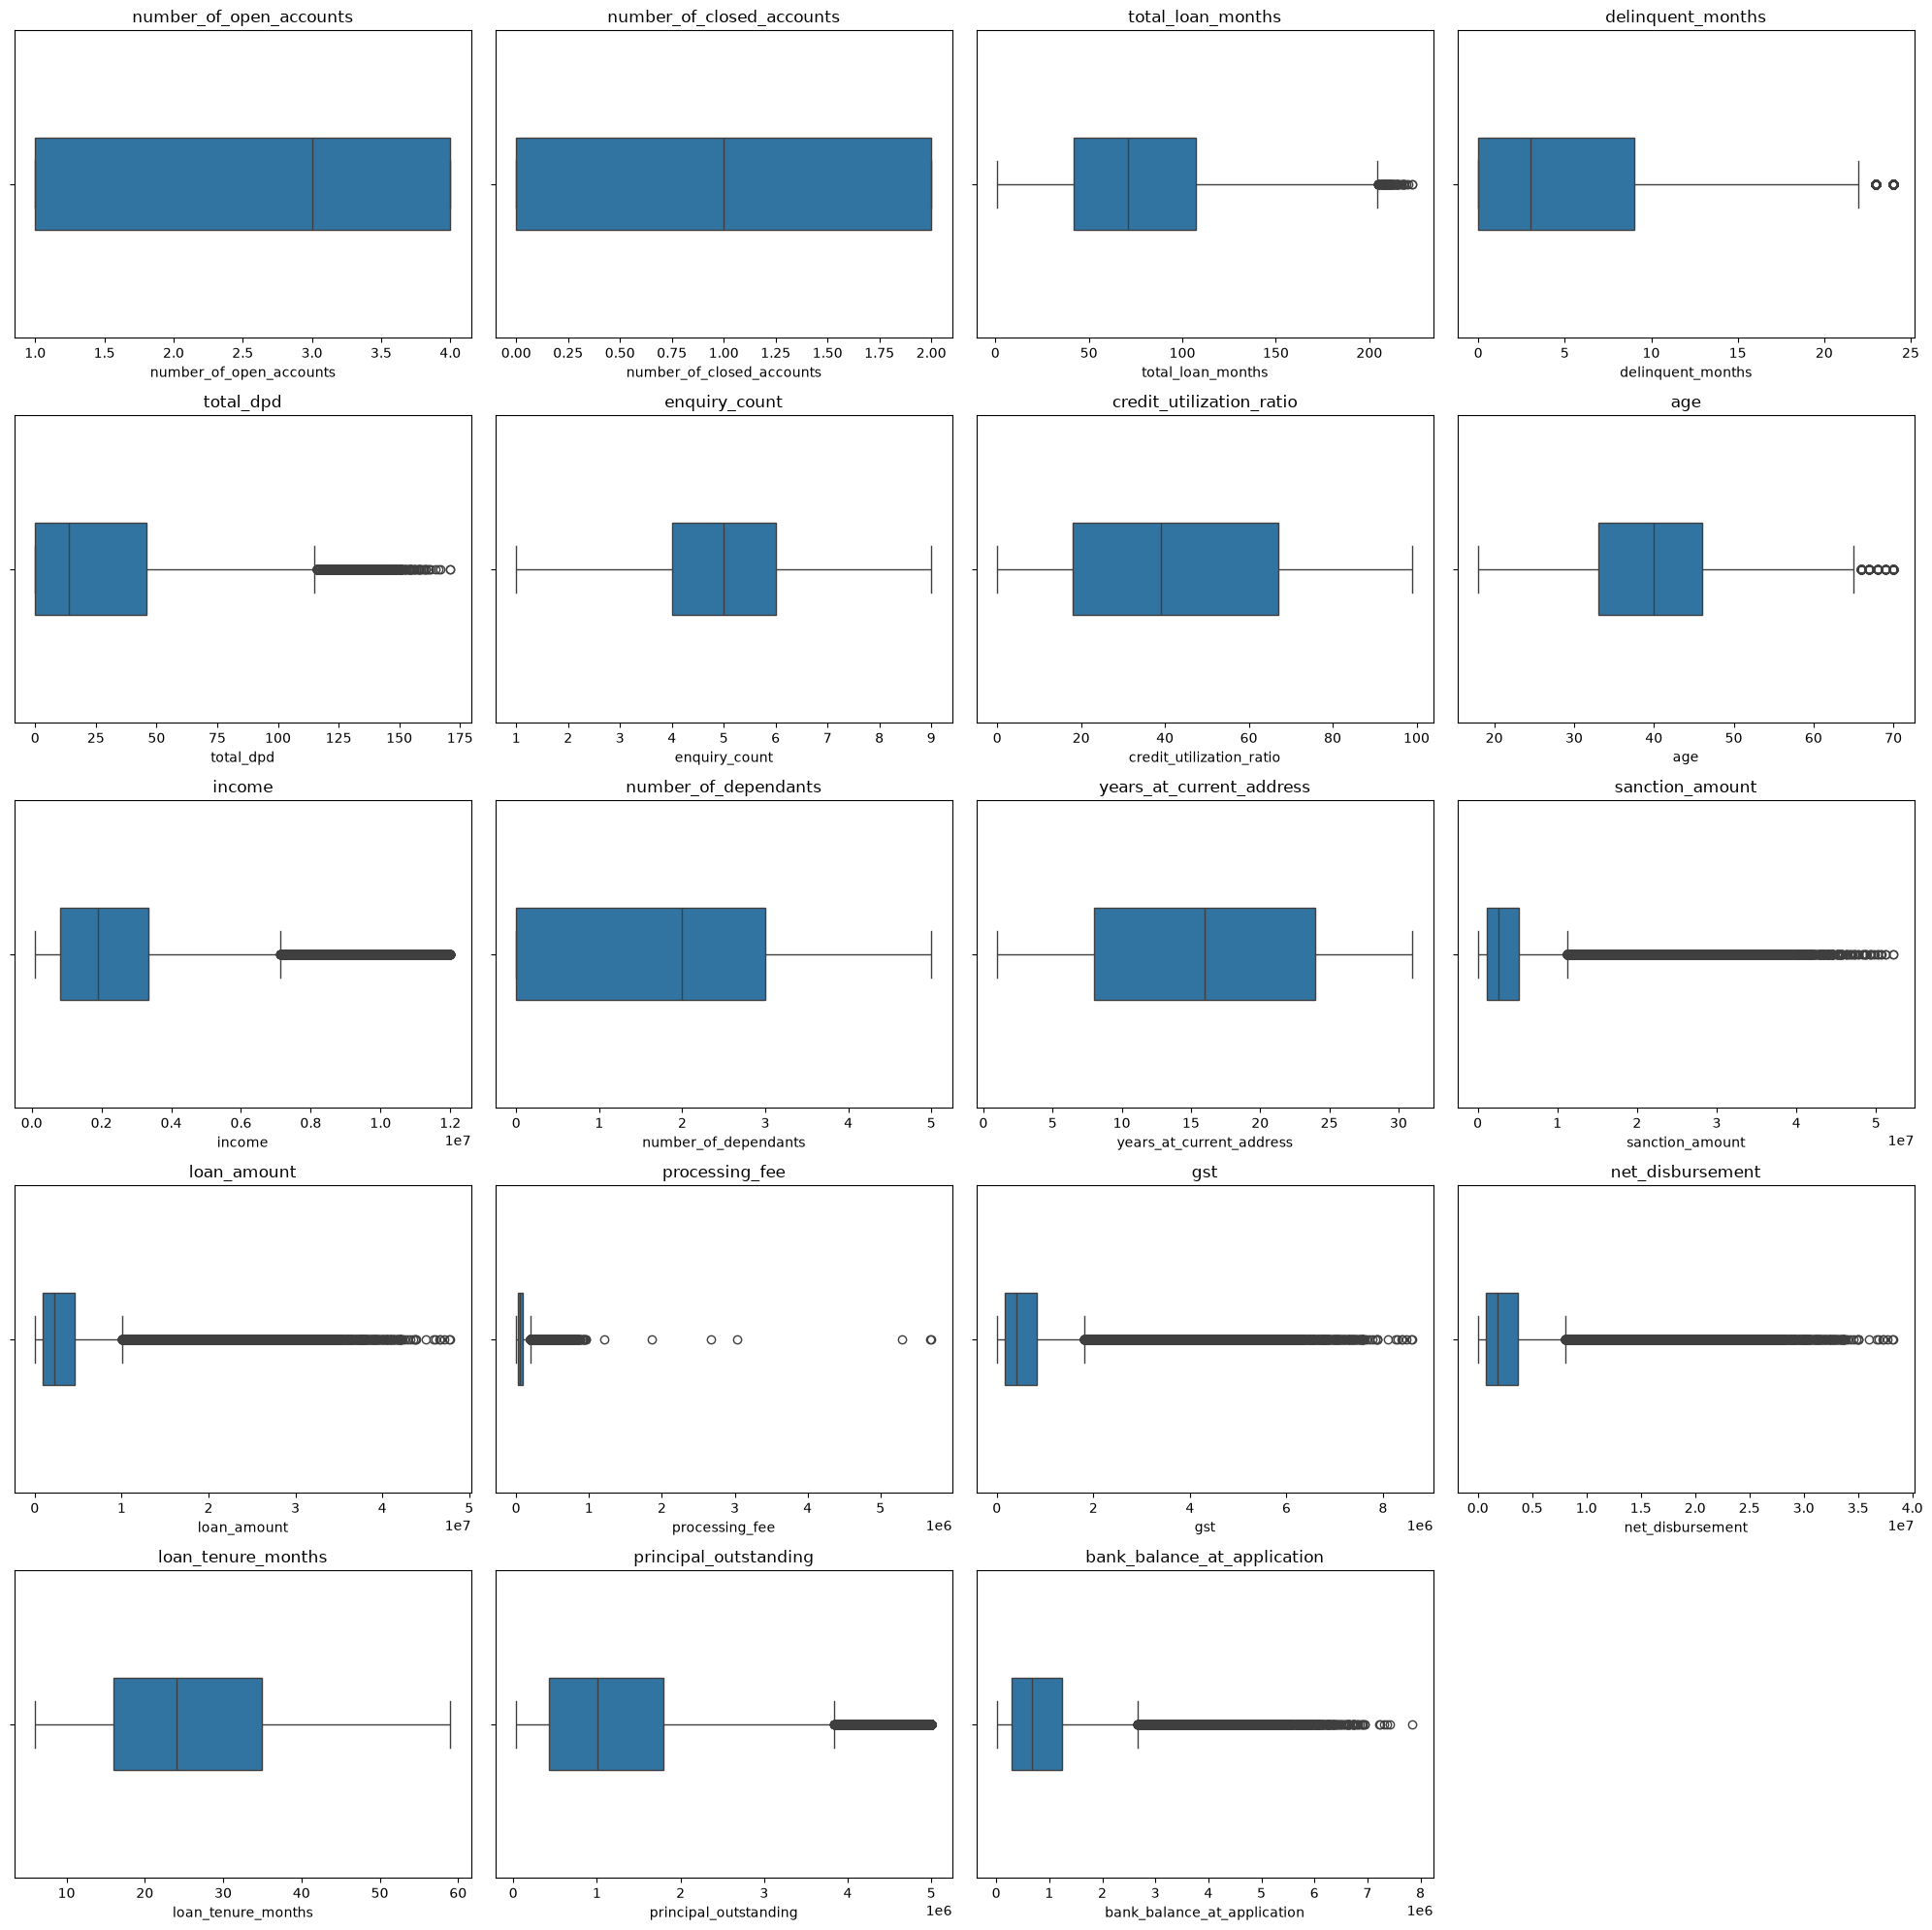

In [32]:
# Used Google Gemini for improving visualization

cols = 4  # Number of columns per row
n = len(num_features)
rows = (n // cols) + int(n % cols != 0)

plt.figure(figsize=(cols * 5, rows * 4))

for i, feature in enumerate(num_features, 1):
    plt.subplot(rows, cols, i)
    sns.boxplot(x=df[feature], width=0.3)  # Added width parameter (default is 0.8)
    plt.title(feature)

plt.tight_layout()
plt.show()

- Tree Based Models are robust to Outliers

- Outliers will impact Scaling

#### `Feature Engineering : Feature Creation`

---
> `Input from the NBFC Client`
- > `Loan to Income Ratio is a better metric compared to loan amount and income individually`

- > `Delinquent Months to Loan Months is a better metric compared to delinquent months and loan months individually`

- > `Average DPD per Delinquent Month is a better metric compared to total dpd (days past due) and total delinquent months individually`
---

- `Three new features need to be created`
    - `loan_to_income           : Loan to Income Ratio`
    - `delinquency_ratio        : Delinquent Months to Loan Months`
    - `avg_dpd_per_delinquency  : Average DPD per Delinquent Month`

- `After creation of these new feature, we shall drop the features which were used for extraction`

- `Since we're dropping features, we need to make sure that any feature highly correlated with them must also be dropped (Realised this when I was left with 'net_disbursement' at the end of Feature Engineering, came back here and did this step)`

In [33]:
# Creating Features as per client input

df['loan_to_income'] = df['loan_amount']/df['income']

df['delinquency_ratio'] = df['delinquent_months']/df['total_loan_months']

df['avg_dpd_per_delinquency'] = df['total_dpd']/df['delinquent_months']

In [34]:
# Need to check since we've created new features by doing mathematical operations

df.isnull().sum()

number_of_open_accounts            0
number_of_closed_accounts          0
total_loan_months                  0
delinquent_months                  0
total_dpd                          0
enquiry_count                      0
credit_utilization_ratio           0
age                                0
gender                             0
marital_status                     0
employment_status                  0
income                             0
number_of_dependants               0
residence_type                     0
years_at_current_address           0
city                               0
loan_purpose                       0
loan_type                          0
sanction_amount                    0
loan_amount                        0
processing_fee                     0
gst                                0
net_disbursement                   0
loan_tenure_months                 0
principal_outstanding              0
bank_balance_at_application        0
default                            0
l

In [35]:
df[df['delinquent_months']==0].shape

(19993, 30)

In [36]:
# Let's make dpd_per_delinquent_month=0 when delinquent_months=0

df['avg_dpd_per_delinquency'] = df['avg_dpd_per_delinquency'].fillna(0)

In [37]:
df.isnull().sum()

number_of_open_accounts        0
number_of_closed_accounts      0
total_loan_months              0
delinquent_months              0
total_dpd                      0
enquiry_count                  0
credit_utilization_ratio       0
age                            0
gender                         0
marital_status                 0
employment_status              0
income                         0
number_of_dependants           0
residence_type                 0
years_at_current_address       0
city                           0
loan_purpose                   0
loan_type                      0
sanction_amount                0
loan_amount                    0
processing_fee                 0
gst                            0
net_disbursement               0
loan_tenure_months             0
principal_outstanding          0
bank_balance_at_application    0
default                        0
loan_to_income                 0
delinquency_ratio              0
avg_dpd_per_delinquency        0
dtype: int

In [38]:
# Now we need to drop 'loan_amount', 'income', 'delinquent_months', 'total_loan_months', 'total_dpd'
# But let's check correlation once so that we can drop unnecessary columns along
# Focus only on 'loan_amount', 'income', 'delinquent_months', 'total_loan_months', 'total_dpd' for now

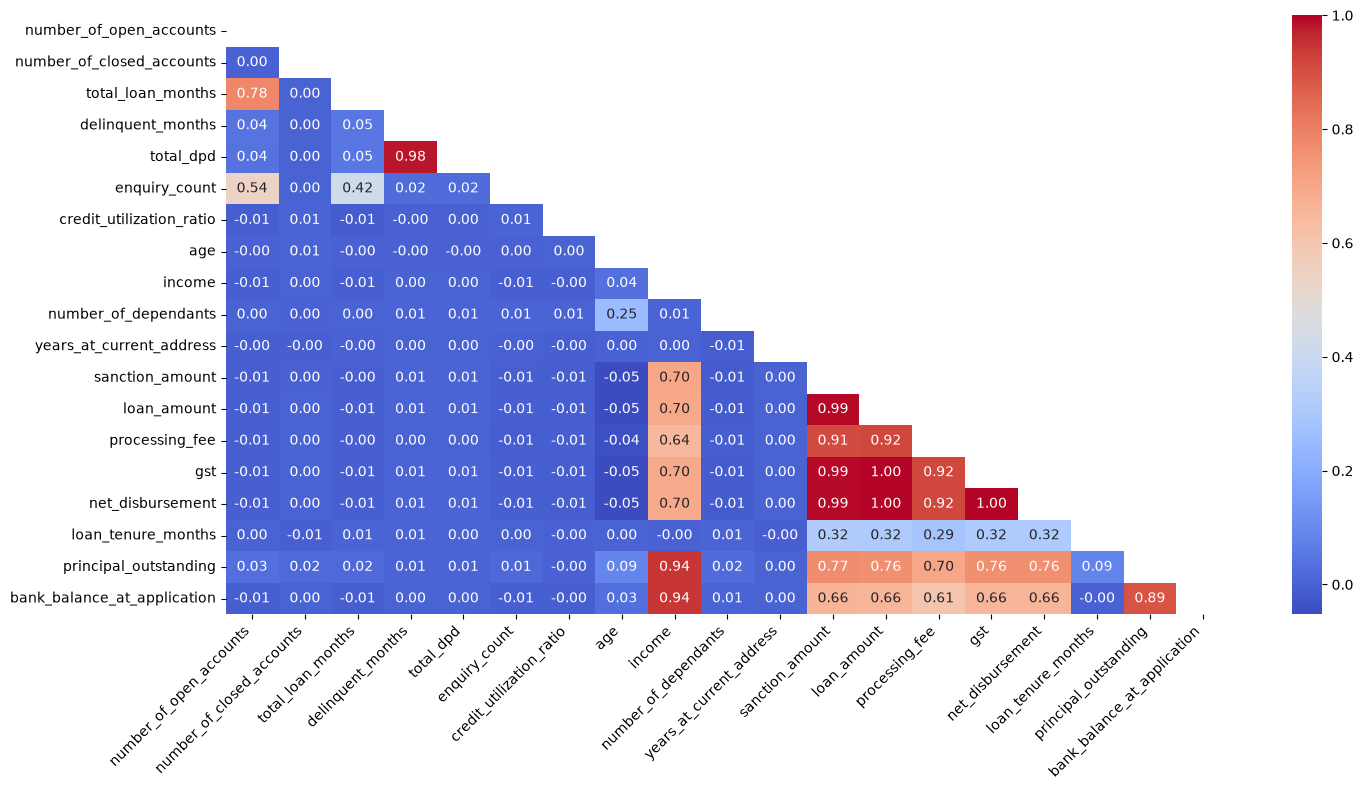

In [39]:
# Correlation Heatmap

plt.figure(figsize=(15, 8))

corr = df[num_features].corr()
mask = np.triu(np.ones_like(corr, dtype=bool), k=0)

sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', mask=mask)

plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

- `sanction_amount, processing_fee, gst, net_disbursement are highly correlated with loan_amount`

- `principal_outstanding, bank_balance_at_application are highly correlated with income`

- `Let's drop all these columns`

In [40]:
# Dropping 'loan_amount', 'income', 'delinquent_months', 'total_loan_months', 'total_dpd'
# Dropping 'sanction_amount', 'processing_fee', 'gst', 'net_disbursement', 'principal_outstanding', 'bank_balance_at_application' (correlated features)

added_new_features = ['loan_to_income', 'delinquency_ratio', 'avg_dpd_per_delinquency']

columns_to_drop = ['loan_amount', 'income', 'delinquent_months', 'total_loan_months', 'total_dpd', 'sanction_amount', 'processing_fee', 'gst', 'net_disbursement', 'principal_outstanding', 'bank_balance_at_application']

df.drop(columns=columns_to_drop, inplace=True)

num_features = [feature for feature in num_features if feature not in columns_to_drop] + added_new_features

In [41]:
df.describe()

,number_of_open_accounts,number_of_closed_accounts,enquiry_count,credit_utilization_ratio,age,number_of_dependants,years_at_current_address,loan_tenure_months,default,loan_to_income,delinquency_ratio,avg_dpd_per_delinquency
count,49992.00,49992.00,49992.00,49992.00,49992.00,49992.00,49992.00,49992.00,49992.00,49992.00,49992.00,49992.00
mean,2.50,1.00,5.01,43.36,39.55,1.94,16.02,25.94,0.09,1.56,0.10,3.30
std,1.12,0.81,2.03,29.36,9.85,1.54,8.93,12.43,0.28,0.97,0.17,2.90
min,1.00,0.00,1.00,0.00,18.00,0.00,1.00,6.00,0.00,0.30,0.00,0.00
25%,1.00,0.00,4.00,18.00,33.00,0.00,8.00,16.00,0.00,0.77,0.00,0.00
50%,3.00,1.00,5.00,39.00,40.00,2.00,16.00,24.00,0.00,1.16,0.04,4.33
75%,4.00,2.00,6.00,67.00,46.00,3.00,24.00,35.00,0.00,2.45,0.13,5.75
max,4.00,2.00,9.00,99.00,70.00,5.00,31.00,59.00,1.00,4.59,1.00,10.00


In [42]:
print(df.shape)
print(len(num_features) + len(cat_features))

(49992, 19)
18


#### `Train-Test Split`

In [43]:
# Train Test Split to prevent Data Leakage

X = df.drop(columns=['default'])
y = df['default']

X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.7, test_size=0.3, random_state=10, stratify=y)   # stratify=y because this is imbalanced dataset

X_train.shape, X_test.shape, y_train.shape, y_test.shape

((34994, 18), (14998, 18), (34994,), (14998,))

In [44]:
df_checkpoint = df.copy()

`Creating the new dataframe 'df' to perform EDA`

In [45]:
# Creatin the new df on which we'll perform EDA

df = pd.concat([X_train, y_train], axis=1)

In [46]:
print(df.shape)
print(len(num_features),':',num_features)
print(len(cat_features),':',cat_features)

(34994, 19)
11 : ['number_of_open_accounts', 'number_of_closed_accounts', 'enquiry_count', 'credit_utilization_ratio', 'age', 'number_of_dependants', 'years_at_current_address', 'loan_tenure_months', 'loan_to_income', 'delinquency_ratio', 'avg_dpd_per_delinquency']
7 : ['gender', 'marital_status', 'employment_status', 'residence_type', 'city', 'loan_purpose', 'loan_type']


#### `EDA`

##### <h5 align='center'> __Univariate__ </h5>

__Numerical Features__

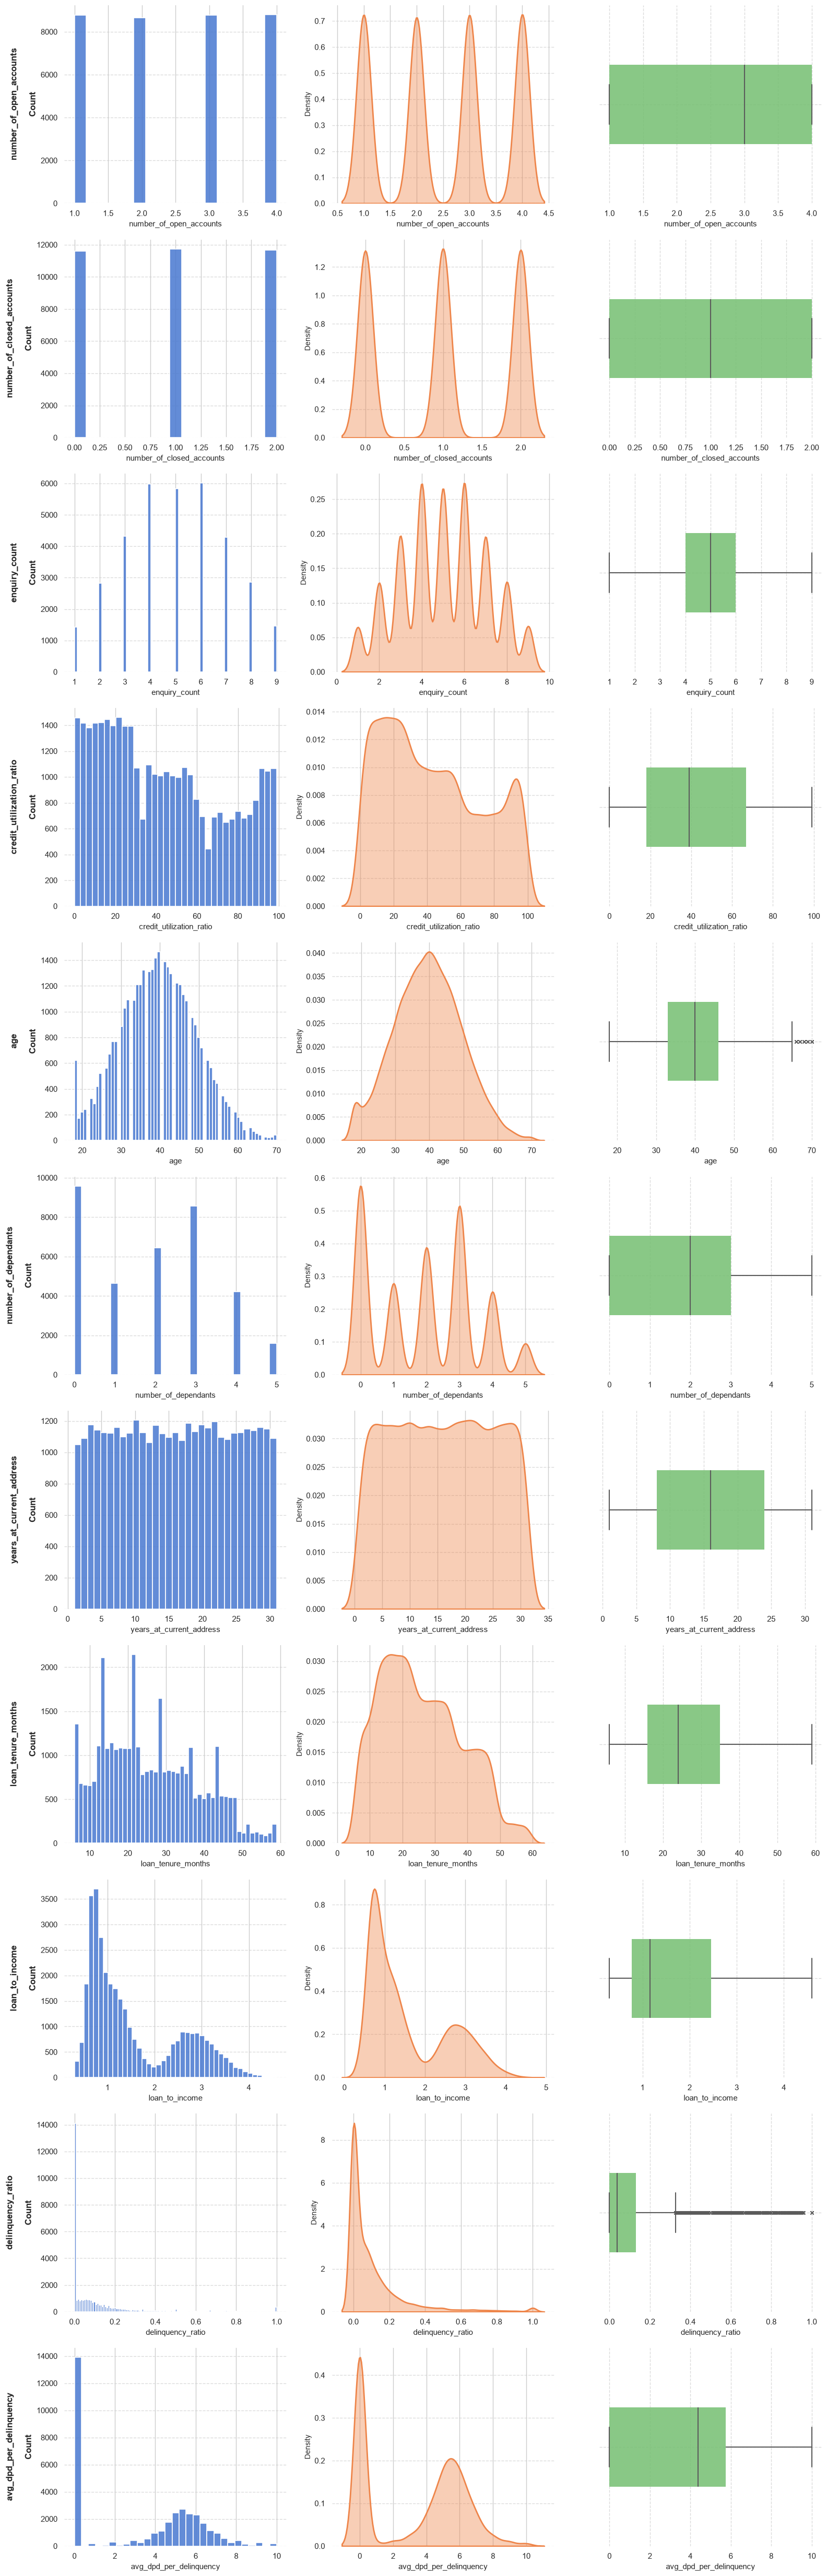

In [47]:
# Used Google Gemini to produce this code for visualization

def plot_num_features(df, num_features):
    # Set a clean, modern aesthetic base
    sns.set_theme(style="whitegrid", context="notebook")
    
    n = len(num_features)
    
    # 1. Choose a cohesive, sophisticated color palette
    # Using a single professional palette (like 'crest' or 'mako') or a soft muted palette
    colors = sns.color_palette("muted", 3) 
    
    # Create the figure with extra room for clean spacing
    fig, axes = plt.subplots(nrows=n, ncols=3, figsize=(16, 4.5 * n))
    
    # Ensure axes is always a 2D array even if n == 1
    if n == 1:
        axes = axes.reshape(1, 3)
        
    for i, col in enumerate(num_features):
        data = df[col].dropna()  # Dropping NaNs prevents plotting issues
        
        # --- 1. HISTOGRAM ---
        # Added edge color and light transparency for a cleaner look
        sns.histplot(data, ax=axes[i, 0], kde=False, color=colors[0], 
                     edgecolor='white', linewidth=1.2, alpha=0.85)
        #axes[i, 0].set_title("Distribution (Histogram)", fontsize=12, fontweight='bold', pad=10)
        axes[i, 0].set_ylabel("Count", fontsize=10)
        
        # --- 2. KDE PLOT ---
        # Added a slightly darker border to make the density area pop
        sns.kdeplot(data, ax=axes[i, 1], fill=True, color=colors[1], 
                    alpha=0.4, linewidth=2)
        #axes[i, 1].set_title("Density (KDE Plot)", fontsize=12, fontweight='bold', pad=10)
        axes[i, 1].set_ylabel("Density", fontsize=10)
        
        # --- 3. BOX PLOT ---
        # Styled the boxplot with thinner lines, a subtle width, and styled fliers (outliers)
        sns.boxplot(x=data, ax=axes[i, 2], color=colors[2], width=0.4,
                    flierprops={"marker": "x", "markerfacecolor": "gray", "markersize": 5},
                    boxprops={"edgecolor": "none", "alpha": 0.85},
                    linewidth=1.5)
        #axes[i, 2].set_title("Spread & Outliers (Box Plot)", fontsize=12, fontweight='bold', pad=10)
        
        # --- Row-level adjustments ---
        # Add a prominent Y-axis label on the far left to identify the feature clearly
        axes[i, 0].set_ylabel(f"{col}\n\nCount", fontsize=12, fontweight='bold')
        
        # Clean up X-axis labels (remove repetitive titles, keep it tidy)
        for j in range(3):
            axes[i, j].set_xlabel(col, fontsize=11)
            # Despine to make it look lightweight and modern
            sns.despine(ax=axes[i, j], left=True, bottom=True)
            # Subtle grid adjustments
            axes[i, j].grid(True, axis='y', linestyle='--', alpha=0.7)
            if j == 2: # Boxplot grid makes more sense on the X axis
                axes[i, j].grid(True, axis='x', linestyle='--', alpha=0.7)

    # Prevent overlapping text elements
    plt.tight_layout()
    plt.show()

plot_num_features(df, num_features)


- `Features for Min-Max Scaling :`

    - `Bound features (value falls in a predefined range) - 'credit_utilization_ratio', 'delinquency_ratio'`

    - `Just divide 'credit_utilization_ratio' by 100 and it's fine in this case`

- `Features which might need log transformation before Standard Scaling :`

    - `'loan_tenure_months', 'loan_to_income', 'avg_dpd_per_delinquency'`

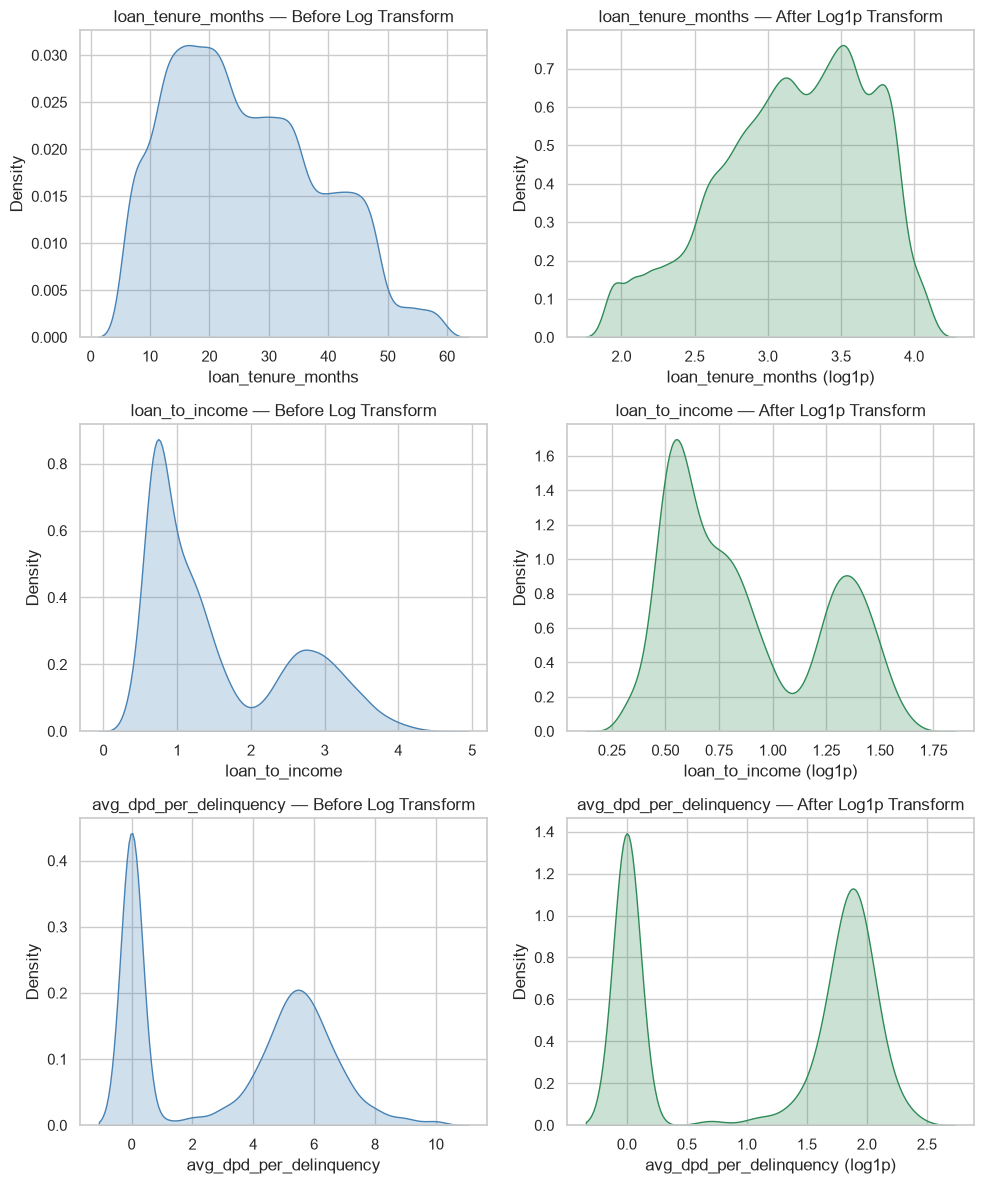

In [48]:
# Log Transformation

ltf_list = ['loan_tenure_months', 'loan_to_income', 'avg_dpd_per_delinquency']

n_features = len(ltf_list)
fig, axes = plt.subplots(n_features, 2, figsize=(10, 4 * n_features))
axes = np.atleast_2d(axes)  # ensures axes works even for single feature

for i, feature in enumerate(ltf_list):
    # Original feature
    data = df[feature].dropna()
    
    # Log1p transformed (handles zeros safely)
    data_log = np.log1p(data)
    
    # --- Before transformation ---
    sns.kdeplot(data, ax=axes[i, 0], fill=True, color='steelblue')
    axes[i, 0].set_title(f"{feature} — Before Log Transform", fontsize=12)
    axes[i, 0].set_xlabel(feature)
    
    # --- After transformation ---
    sns.kdeplot(data_log, ax=axes[i, 1], fill=True, color='seagreen')
    axes[i, 1].set_title(f"{feature} — After Log1p Transform", fontsize=12)
    axes[i, 1].set_xlabel(feature + " (log1p)")
    
plt.tight_layout()
plt.show()

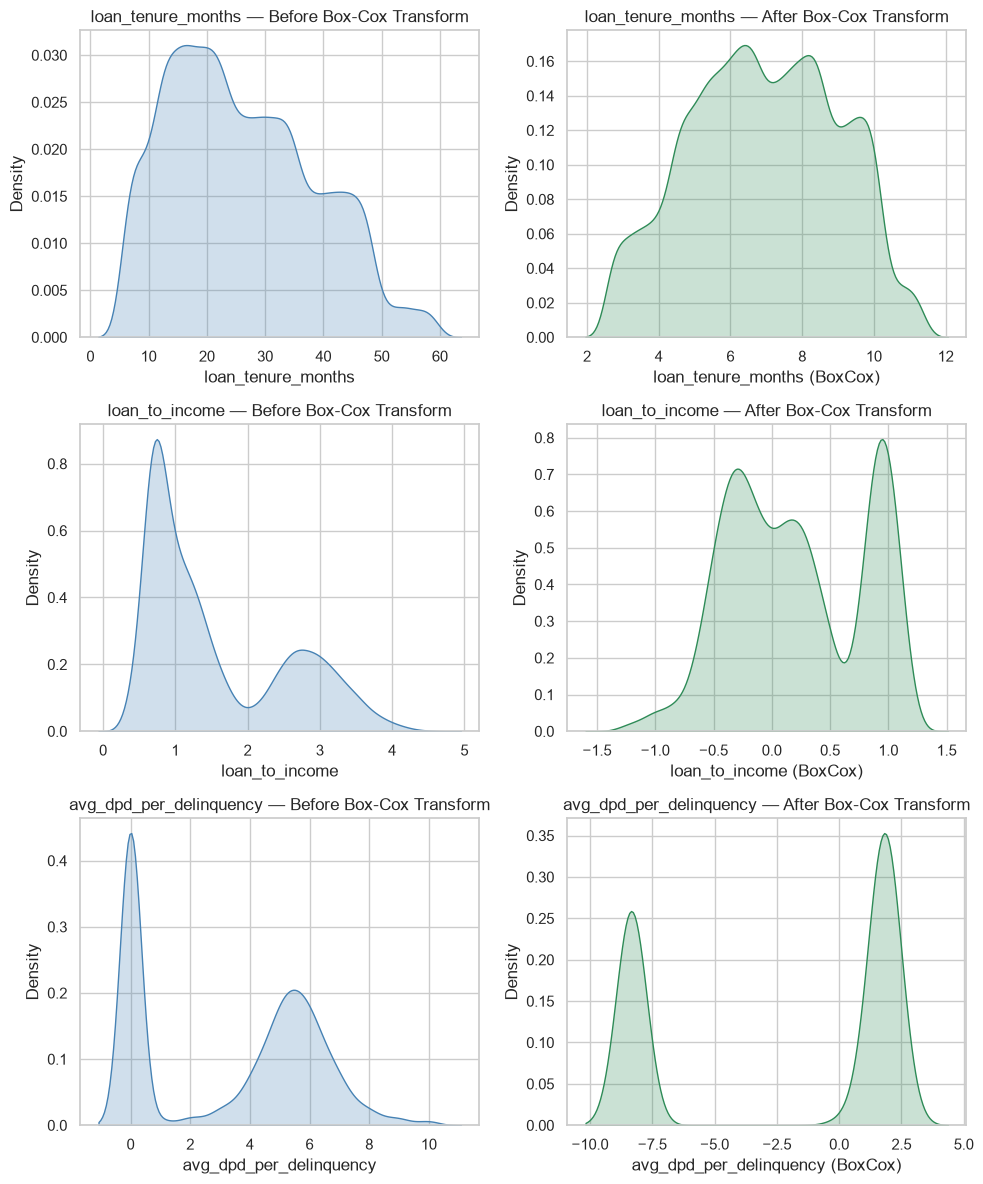

In [49]:
# Box-Cox Transformation

bcf_list = ['loan_tenure_months', 'loan_to_income', 'avg_dpd_per_delinquency']

from scipy.stats import boxcox
n_features = len(bcf_list)
fig, axes = plt.subplots(n_features, 2, figsize=(10, 4 * n_features))
axes = np.atleast_2d(axes)  # ensures axes works even for single feature

for i, feature in enumerate(bcf_list):
    # Original feature
    data = df[feature]                        

    # BoxCox
    data_bc, _ = boxcox(data.values + 0.000001)       # Added 0.000001 to make 0s positive
    
    # --- Before transformation ---
    sns.kdeplot(data, ax=axes[i, 0], fill=True, color='steelblue')
    axes[i, 0].set_title(f"{feature} — Before Box-Cox Transform", fontsize=12)
    axes[i, 0].set_xlabel(feature)
    
    # --- After transformation ---
    sns.kdeplot(data_bc, ax=axes[i, 1], fill=True, color='seagreen')
    axes[i, 1].set_title(f"{feature} — After Box-Cox Transform", fontsize=12)
    axes[i, 1].set_xlabel(feature + " (BoxCox)")
    
plt.tight_layout()
plt.show()

__Categorical Features__

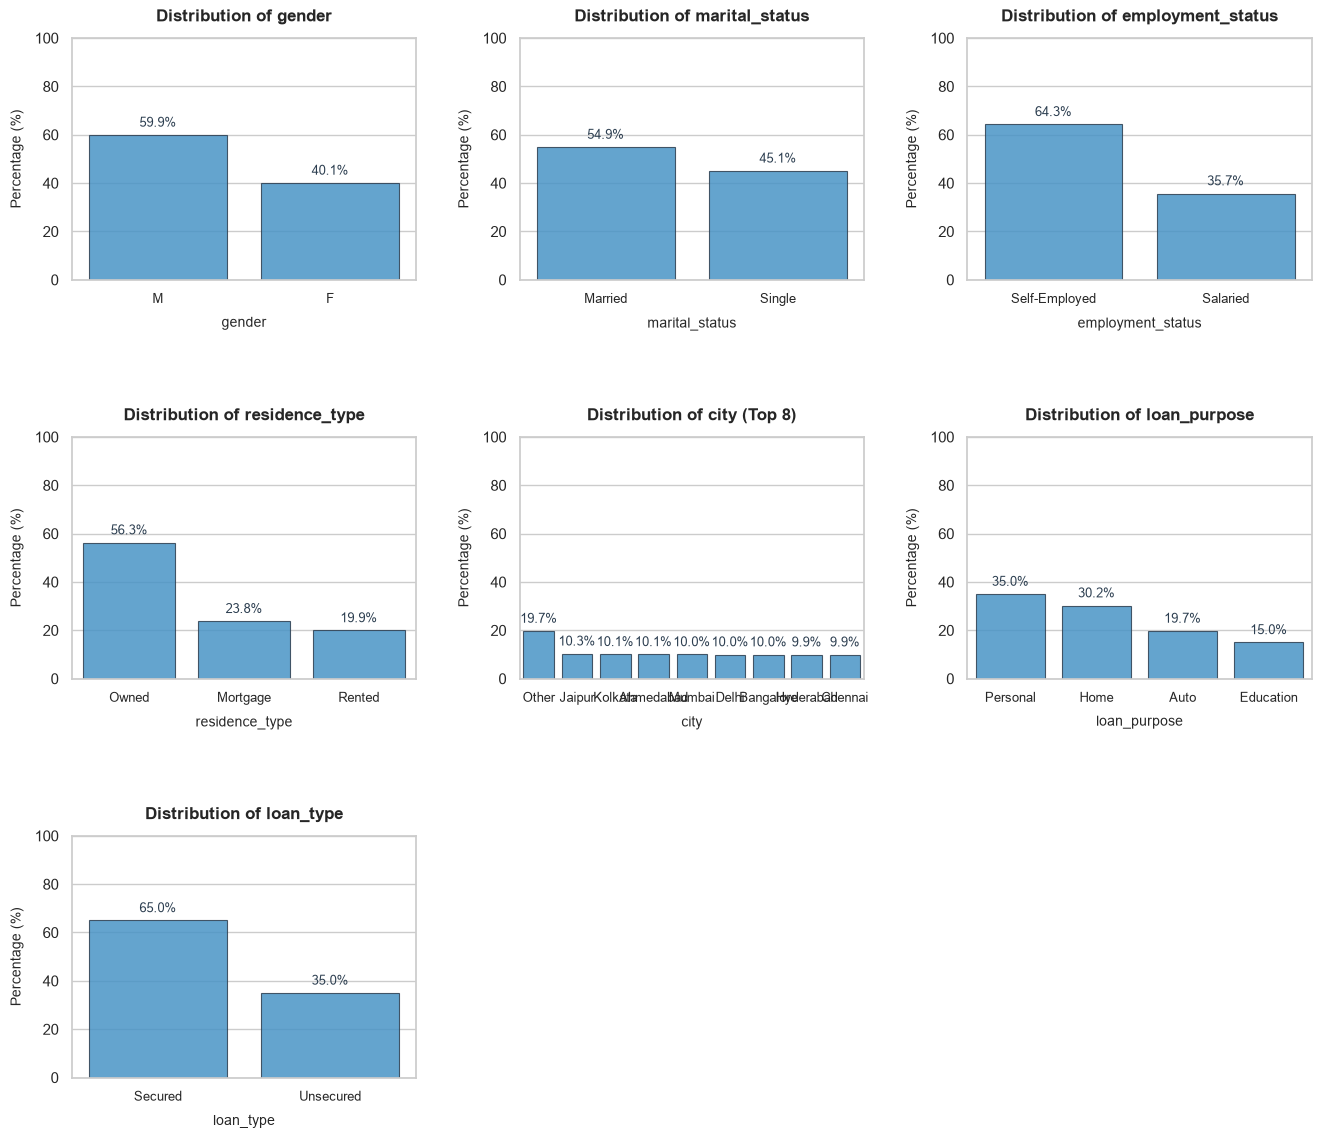

In [50]:
# Code generated using Google Gemini

def plot_cat_features(df, cat_features, max_categories=8, n_cols=3):
    n_features = len(cat_features)
    if n_features == 0:
        print("No categorical features provided.")
        return

    # Dynamically calculate rows needed based on feature count
    n_rows = math.ceil(n_features / n_cols)
    
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 4.5 * n_rows))
    
    # Ensure axes is always a flat array even if there's only 1 feature
    if n_features == 1:
        axes = [axes]
    else:
        axes = axes.flatten()

    for i, col in enumerate(cat_features):
        ax = axes[i]
        
        if col not in df.columns:
            ax.set_visible(False)
            continue
            
        # Handle missing values explicitly and convert everything to string
        series = df[col].fillna("Missing").astype(str)
        
        # Limit high-cardinality features to top N categories + Other
        if series.nunique() > max_categories:
            top_cats = series.value_counts().nlargest(max_categories).index
            series = series.apply(lambda x: x if x in top_cats else "Other")
            title_suffix = f" (Top {max_categories})"
        else:
            title_suffix = ""

        # Calculate percentage for each category
        pct_df = series.value_counts(normalize=True).mul(100).reset_index()
        pct_df.columns = ['Category', 'Percentage']
        
        # Create the bar plot with modern styling
        sns.barplot(
            x='Category', 
            y='Percentage', 
            data=pct_df, 
            ax=ax, 
            color='#3498db',  # Clean modern blue
            edgecolor='#2c3e50',
            linewidth=0.8,
            alpha=0.85
        )
        
        # Customize titles and labels with clean padding
        ax.set_title(f'Distribution of {col}{title_suffix}', fontsize=12, fontweight='bold', pad=12)
        ax.set_xlabel(col, fontsize=10, labelpad=8)
        ax.set_ylabel('Percentage (%)', fontsize=10, labelpad=8)
        ax.set_ylim(0, 100)  # Standardize y-axis to 100%
        
        # Fix UserWarning by explicitly setting ticks first, then apply horizontal labels with text wrapping
        ax.set_xticks(range(len(pct_df)))
        labels = pct_df['Category'].astype(str).tolist()
        wrapped_labels = ['\n'.join(label.split()) if ' ' in label else label for label in labels]
        
        ax.set_xticklabels(
            wrapped_labels, 
            rotation=0, 
            ha='center', 
            fontsize=9
        )
        
        # Add percentage text labels directly on top of each bar
        for p in ax.patches:
            height = p.get_height()
            if height > 0:
                ax.annotate(
                    f'{height:.1f}%',
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom',
                    fontsize=9, color='#2c3e50',
                    xytext=(0, 4),
                    textcoords='offset points'
                )

    # Remove any unused subplot slots dynamically
    for j in range(n_features, len(axes)):
        fig.delaxes(axes[j])

    # Increase gaps between the graphs for a clean, isolated look
    plt.subplots_adjust(hspace=0.65, wspace=0.30)
    plt.show()

plot_cat_features(df, cat_features)

##### <h5 align='center'> __Bivariate__ </h5>

---
##### __Numerical vs Numerical__

In [51]:
df[num_features].corr()

,number_of_open_accounts,number_of_closed_accounts,enquiry_count,credit_utilization_ratio,age,number_of_dependants,years_at_current_address,loan_tenure_months,loan_to_income,delinquency_ratio,avg_dpd_per_delinquency
number_of_open_accounts,1.00,0.00,0.54,-0.01,-0.00,0.00,-0.01,0.00,0.00,-0.33,-0.00
number_of_closed_accounts,0.00,1.00,0.01,0.00,0.00,0.00,-0.00,-0.01,-0.01,-0.00,0.01
enquiry_count,0.54,0.01,1.00,-0.00,-0.00,0.01,0.00,0.00,0.00,-0.18,-0.00
credit_utilization_ratio,-0.01,0.00,-0.00,1.00,0.01,0.01,-0.01,0.00,-0.01,-0.00,-0.00
age,-0.00,0.00,-0.00,0.01,1.00,0.26,-0.00,-0.00,-0.17,0.00,0.01
number_of_dependants,0.00,0.00,0.01,0.01,0.26,1.00,-0.01,0.00,-0.04,0.00,0.01
years_at_current_address,-0.01,-0.00,0.00,-0.01,-0.00,-0.01,1.00,-0.00,0.00,-0.00,0.01
loan_tenure_months,0.00,-0.01,0.00,0.00,-0.00,0.00,-0.00,1.00,0.63,-0.00,-0.00
loan_to_income,0.00,-0.01,0.00,-0.01,-0.17,-0.04,0.00,0.63,1.00,-0.01,-0.00
delinquency_ratio,-0.33,-0.00,-0.18,-0.00,0.00,0.00,-0.00,-0.00,-0.01,1.00,0.45


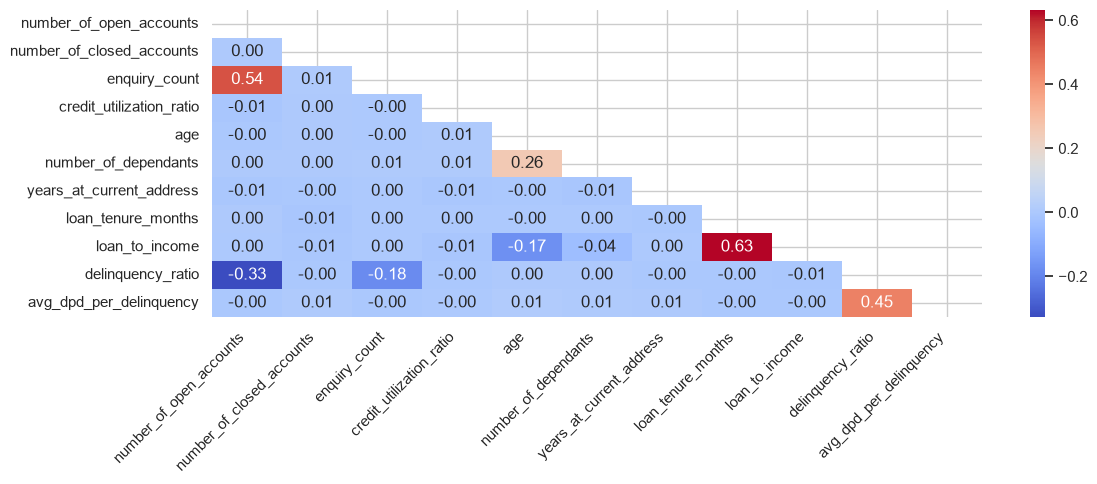

In [52]:
# Correlation Heatmap

plt.figure(figsize=(12, 5))

corr = df[num_features].corr()
mask = np.triu(np.ones_like(corr, dtype=bool), k=0)

sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', mask=mask)

plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [53]:
print(df.shape)
print(len(num_features) + len(cat_features))

(34994, 19)
18


---
##### __Numerical vs Target__

In [54]:
for feature in num_features:
    print(f'default vs {feature}')
    print(df.groupby('default')[feature].describe().to_string(), '\n\n')  #.to_string() used to print in single line

# Check the distribution, mean, std deviation across target labels

default vs number_of_open_accounts
           count  mean  std  min  25%  50%  75%  max
default                                             
0       31986.00  2.53 1.12 1.00 2.00 3.00 4.00 4.00
1        3008.00  2.23 1.14 1.00 1.00 2.00 3.00 4.00 


default vs number_of_closed_accounts
           count  mean  std  min  25%  50%  75%  max
default                                             
0       31986.00  1.00 0.81 0.00 0.00 1.00 2.00 2.00
1        3008.00  1.02 0.82 0.00 0.00 1.00 2.00 2.00 


default vs enquiry_count
           count  mean  std  min  25%  50%  75%  max
default                                             
0       31986.00  5.01 2.02 1.00 4.00 5.00 6.00 9.00
1        3008.00  4.97 2.10 1.00 3.00 5.00 6.00 9.00 


default vs credit_utilization_ratio
           count  mean   std  min   25%   50%   75%   max
default                                                  
0       31986.00 39.69 27.35 0.00 17.00 35.00 59.00 99.00
1        3008.00 81.73 21.89 0.00 78.00 91.00 96

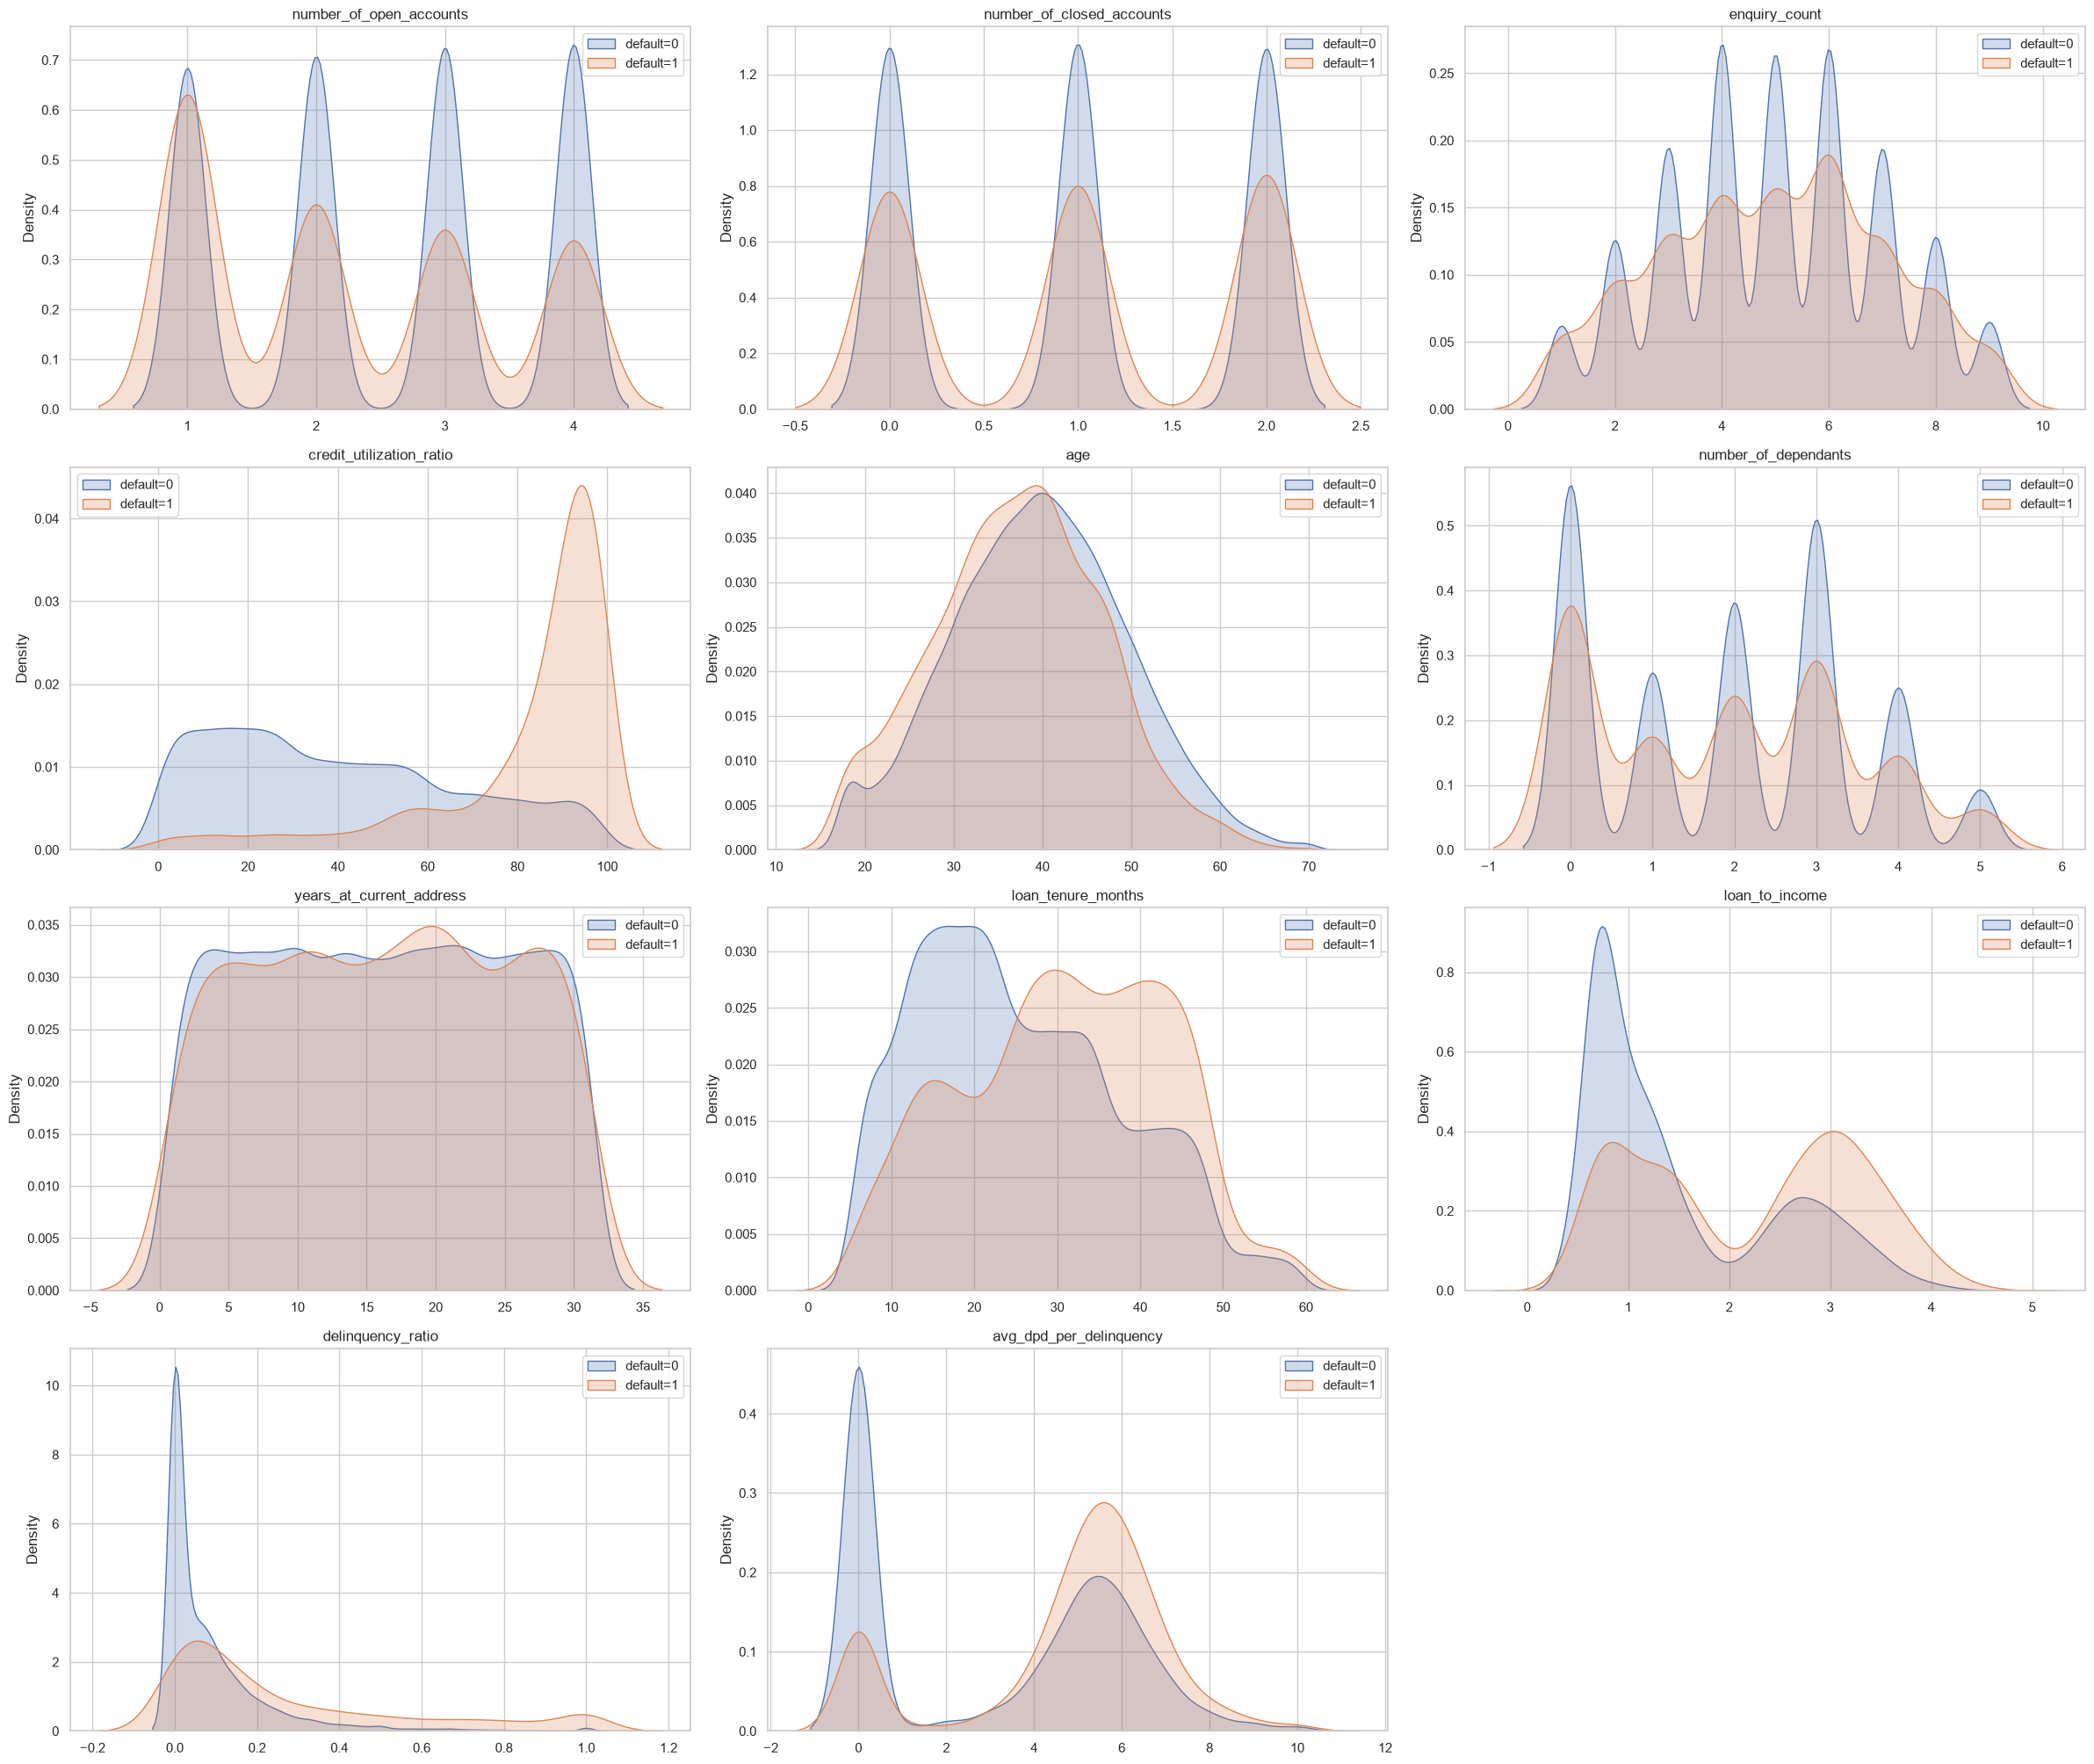

In [55]:
# KDE for all num_features with 'default' as hue

plt.figure(figsize=(24, 30))  # Width, height in inches

for i, col in enumerate(num_features):
    plt.subplot(6, 3, i+1) 
    sns.kdeplot(df[col][df['default']==0], fill=True, label='default=0')
    sns.kdeplot(df[col][df['default']==1], fill=True, label='default=1')
    plt.title(col)        
    plt.xlabel('')
    plt.legend()
   
plt.tight_layout()
plt.show()

---
##### __Categorical vs Categorical__

In [56]:
for feature in cat_features:
    for i in cat_features:
        if i != feature:
            print(pd.crosstab(df[feature], df[i], normalize='index').to_string(), '\n \n')

marital_status  Married  Single
gender                         
F                  0.55    0.45
M                  0.55    0.45 
 

employment_status  Salaried  Self-Employed
gender                                    
F                      0.36           0.64
M                      0.36           0.64 
 

residence_type  Mortgage  Owned  Rented
gender                                 
F                   0.24   0.57    0.19
M                   0.23   0.56    0.20 
 

city    Ahmedabad  Bangalore  Chennai  Delhi  Hyderabad  Jaipur  Kolkata  Lucknow  Mumbai  Pune
gender                                                                                         
F            0.10       0.10     0.10   0.10       0.10    0.10     0.11     0.10    0.10  0.10
M            0.10       0.10     0.10   0.10       0.10    0.10     0.10     0.10    0.10  0.10 
 

loan_purpose  Auto  Education  Home  Personal
gender                                       
F             0.20       0.15  0.30      0.35
M 

In [ ]:
# Observation : Personal Loans are ALWAYS Unsecured

# loan_type     Secured  Unsecured
# loan_purpose                    
# Auto             1.00       0.00
# Education        1.00       0.00
# Home             1.00       0.00
# Personal         0.00       1.00 

# loan_purpose  Auto  Education  Home  Personal
# loan_type                                    
# Secured       0.30       0.23  0.47      0.00
# Unsecured     0.00       0.00  0.00      1.00 

---
##### __Categorical vs Target__

In [57]:
for feature in cat_features:
    print(pd.crosstab(df[feature], df['default'], normalize='index').to_string(), '\n \n')

default    0    1
gender           
F       0.91 0.09
M       0.92 0.08 
 

default           0    1
marital_status          
Married        0.92 0.08
Single         0.91 0.09 
 

default              0    1
employment_status          
Salaried          0.91 0.09
Self-Employed     0.92 0.08 
 

default           0    1
residence_type          
Mortgage       0.91 0.09
Owned          0.94 0.06
Rented         0.83 0.17 
 

default      0    1
city               
Ahmedabad 0.91 0.09
Bangalore 0.91 0.09
Chennai   0.91 0.09
Delhi     0.92 0.08
Hyderabad 0.92 0.08
Jaipur    0.91 0.09
Kolkata   0.92 0.08
Lucknow   0.92 0.08
Mumbai    0.91 0.09
Pune      0.91 0.09 
 

default         0    1
loan_purpose          
Auto         0.96 0.04
Education    0.90 0.10
Home         0.85 0.15
Personal     0.95 0.05 
 

default      0    1
loan_type          
Secured   0.89 0.11
Unsecured 0.95 0.05 
 



In [58]:
for feature in cat_features:
    print(pd.crosstab(df['default'], df[feature], normalize='index').to_string(), '\n \n')

gender     F    M
default          
0       0.40 0.60
1       0.41 0.59 
 

marital_status  Married  Single
default                        
0                  0.55    0.45
1                  0.52    0.48 
 

employment_status  Salaried  Self-Employed
default                                   
0                      0.35           0.65
1                      0.38           0.62 
 

residence_type  Mortgage  Owned  Rented
default                                
0                   0.24   0.58    0.18
1                   0.26   0.36    0.38 
 

city     Ahmedabad  Bangalore  Chennai  Delhi  Hyderabad  Jaipur  Kolkata  Lucknow  Mumbai  Pune
default                                                                                         
0             0.10       0.10     0.10   0.10       0.10    0.10     0.10     0.10    0.10  0.10
1             0.11       0.10     0.10   0.09       0.09    0.10     0.10     0.09    0.10  0.10 
 

loan_purpose  Auto  Education  Home  Personal
default       

---
##### __Numerical vs Categorical__

In [59]:
for i in cat_features:
    for j in num_features:
        print(f'{i} vs {j}')
        print(df.groupby(i)[j].describe().to_string(), '\n\n')

gender vs number_of_open_accounts
          count  mean  std  min  25%  50%  75%  max
gender                                             
F      14022.00  2.50 1.12 1.00 1.00 3.00 4.00 4.00
M      20972.00  2.50 1.12 1.00 1.00 3.00 4.00 4.00 


gender vs number_of_closed_accounts
          count  mean  std  min  25%  50%  75%  max
gender                                             
F      14022.00  1.01 0.82 0.00 0.00 1.00 2.00 2.00
M      20972.00  0.99 0.82 0.00 0.00 1.00 2.00 2.00 


gender vs enquiry_count
          count  mean  std  min  25%  50%  75%  max
gender                                             
F      14022.00  5.02 2.03 1.00 4.00 5.00 6.00 9.00
M      20972.00  5.00 2.02 1.00 4.00 5.00 6.00 9.00 


gender vs credit_utilization_ratio
          count  mean   std  min   25%   50%   75%   max
gender                                                  
F      14022.00 43.29 29.26 0.00 18.00 39.00 67.00 99.00
M      20972.00 43.31 29.48 0.00 18.00 39.00 67.00 99.00 


gender 

##### <h5 align='center'> __Multivariate__ </h5>

In [60]:
num_features

['number_of_open_accounts',
 'number_of_closed_accounts',
 'enquiry_count',
 'credit_utilization_ratio',
 'age',
 'number_of_dependants',
 'years_at_current_address',
 'loan_tenure_months',
 'loan_to_income',
 'delinquency_ratio',
 'avg_dpd_per_delinquency']

In [61]:
cat_features

['gender',
 'marital_status',
 'employment_status',
 'residence_type',
 'city',
 'loan_purpose',
 'loan_type']

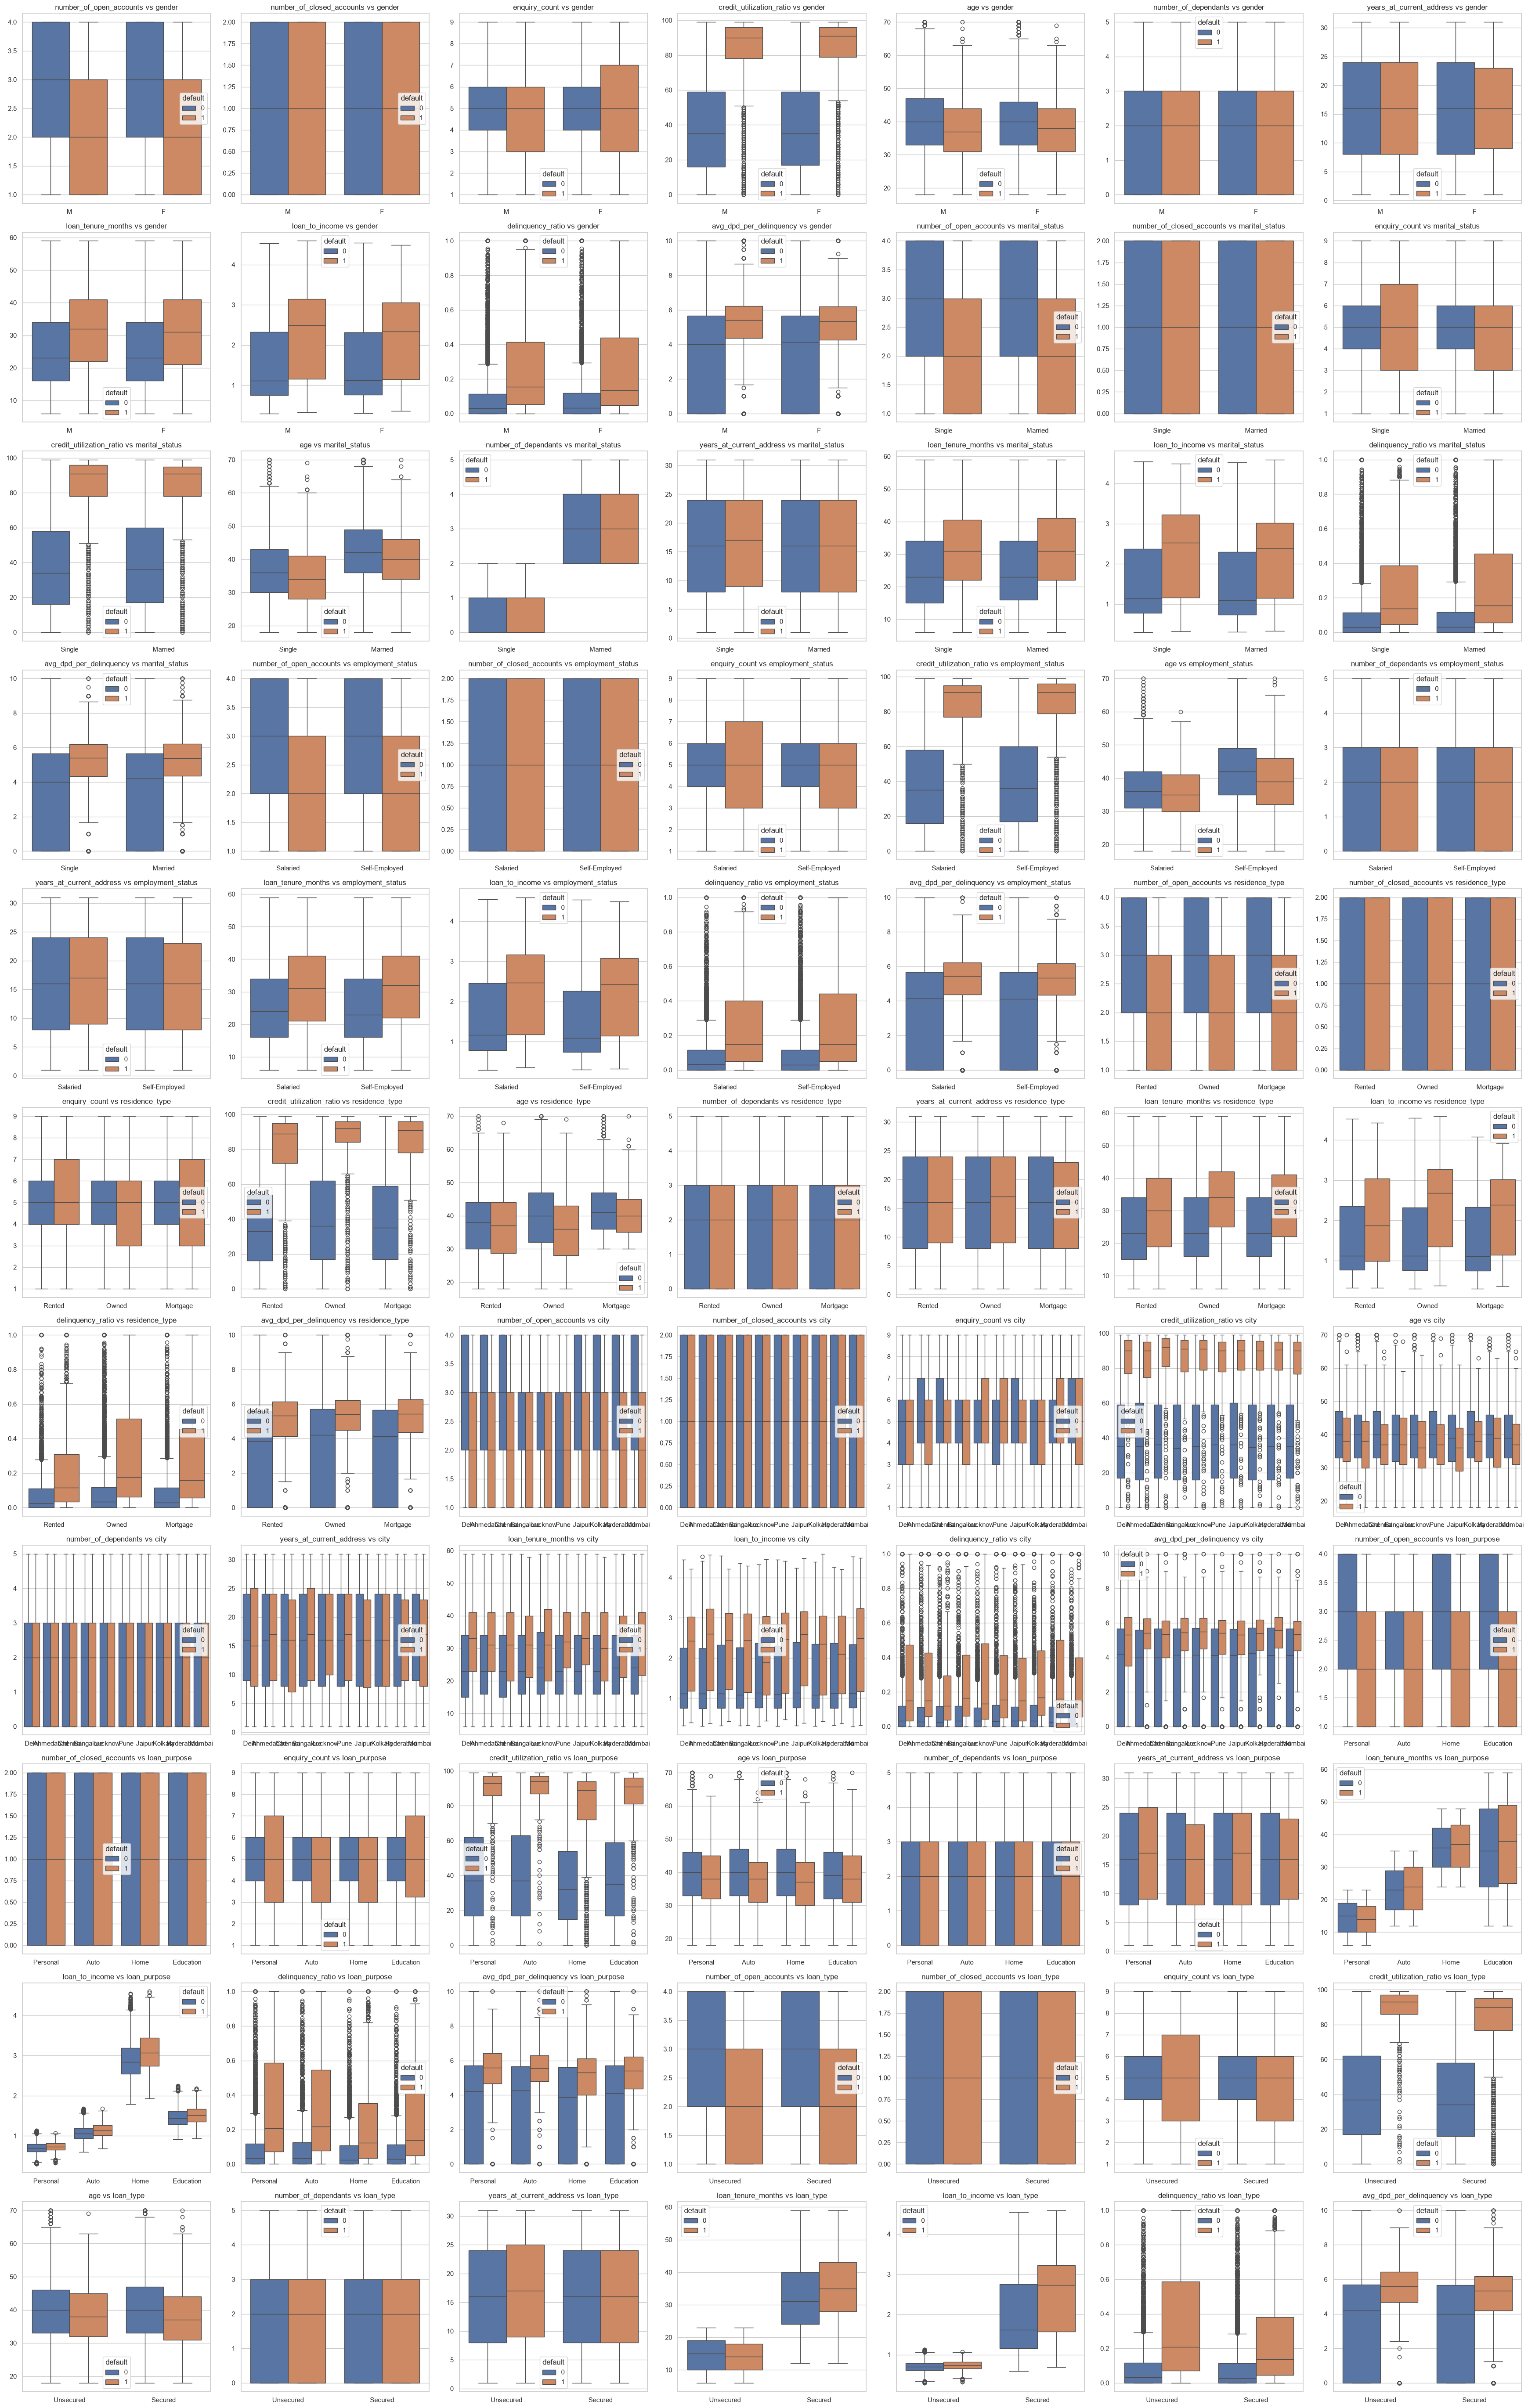

In [62]:
import math

total_plots = len(cat_features) * len(num_features)
cols = 7
rows = math.ceil(total_plots / cols)

# Create subplots grid
fig, axes = plt.subplots(rows, cols, figsize=(5*cols, 5*rows))
axes = axes.flatten()  # flatten for easy indexing

plot_index = 0
for cat_col in cat_features:
    for num_col in num_features:
        ax = axes[plot_index]
        sns.boxplot(
            data=df,
            x=cat_col,
            y=num_col,
            hue='default',
            ax=ax
        )
        ax.set_title(f"{num_col} vs {cat_col}")
        ax.set_xlabel('')
        ax.set_ylabel('')
        plot_index += 1

# Remove any empty subplots (if total_plots < rows*cols)
for i in range(plot_index, len(axes)):
    fig.delaxes(axes[i])

plt.tight_layout()
plt.show()

#### `Feature Engineering : Feature Selection`

In [63]:
df.columns

Index(['number_of_open_accounts', 'number_of_closed_accounts', 'enquiry_count',
       'credit_utilization_ratio', 'age', 'gender', 'marital_status',
       'employment_status', 'number_of_dependants', 'residence_type',
       'years_at_current_address', 'city', 'loan_purpose', 'loan_type',
       'loan_tenure_months', 'loan_to_income', 'delinquency_ratio',
       'avg_dpd_per_delinquency', 'default'],
      dtype='object')

In [64]:
X_train.columns

Index(['number_of_open_accounts', 'number_of_closed_accounts', 'enquiry_count',
       'credit_utilization_ratio', 'age', 'gender', 'marital_status',
       'employment_status', 'number_of_dependants', 'residence_type',
       'years_at_current_address', 'city', 'loan_purpose', 'loan_type',
       'loan_tenure_months', 'loan_to_income', 'delinquency_ratio',
       'avg_dpd_per_delinquency'],
      dtype='object')

In [65]:
df.shape, X_train.shape

((34994, 19), (34994, 18))

In [66]:
num_features, cat_features

(['number_of_open_accounts',
  'number_of_closed_accounts',
  'enquiry_count',
  'credit_utilization_ratio',
  'age',
  'number_of_dependants',
  'years_at_current_address',
  'loan_tenure_months',
  'loan_to_income',
  'delinquency_ratio',
  'avg_dpd_per_delinquency'],
 ['gender',
  'marital_status',
  'employment_status',
  'residence_type',
  'city',
  'loan_purpose',
  'loan_type'])

##### __`WoE and IV`__

In [67]:
# This is for testing every feature individually for predictive power

In [68]:
# df.groupby(['loan_purpose','default']).agg({'default':'count'}).unstack().reset_index().reset_index(drop=True)
# pd.crosstab(df['loan_purpose'], df['default']).reset_index()

In [69]:
# This is applicable only for Binary Classification

def calculate_woe_iv(df, feature, target):

    label_0, label_1 = sorted(df[target].unique())

    ct_df = pd.crosstab(df[feature], df[target]).reset_index()

    # We need to replace 0 to avoid the infinite trap
    ct_df[label_0] = ct_df[label_0].replace(0, 0.0001)
    ct_df[label_1] = ct_df[label_1].replace(0, 0.0001)

    ct_df['proportion_of_0'] = ct_df[label_0]/ct_df[label_0].sum()
    ct_df['proportion_of_1'] = ct_df[label_1]/ct_df[label_1].sum()

    ct_df['woe'] = np.log(ct_df['proportion_of_0']/ct_df['proportion_of_1'])

    ct_df['iv'] = ct_df['woe'] * (ct_df['proportion_of_0'] - ct_df['proportion_of_1'])

    total_iv = ct_df['iv'].sum()

    return total_iv

In [70]:
for feature in cat_features:
    print(f"IV for {feature} : {calculate_woe_iv(df, feature, 'default'):.2f}")    # single quote in f-string ended early, so used double quotes for f-string 

IV for gender : 0.00
IV for marital_status : 0.00
IV for employment_status : 0.00
IV for residence_type : 0.26
IV for city : 0.00
IV for loan_purpose : 0.37
IV for loan_type : 0.16


In [71]:
for feature in num_features:
    # Create a temporary binned column to pass to the function
    df[f'{feature}_binned'] = pd.cut(df[feature], bins=10, labels=False)
    
    iv = calculate_woe_iv(df, f'{feature}_binned', 'default')
    print(f"IV for {feature} : {iv:.2f}")
    
    # Clean up the temporary column afterward
    df.drop(columns=[f'{feature}_binned'], inplace=True)

IV for number_of_open_accounts : 0.08
IV for number_of_closed_accounts : 0.00
IV for enquiry_count : 0.01
IV for credit_utilization_ratio : 2.40
IV for age : 0.07
IV for number_of_dependants : 0.00
IV for years_at_current_address : 0.00
IV for loan_tenure_months : 0.23
IV for loan_to_income : 0.46
IV for delinquency_ratio : 0.68
IV for avg_dpd_per_delinquency : 0.40


`Since IV < 0.02 implies the feature has no predictive power, let's drop these columns : `
- `Categorical  : gender, marital_status, employment_status, city`
- `Numerical    : number_of_closed_accounts, enquiry_count, number_of_dependants, years_at_current_address`

In [ ]:
# Dropping columns with no predictive power

df = df.drop(columns=['gender', 'marital_status', 'employment_status', 'city', 'number_of_closed_accounts', 'enquiry_count', 'number_of_dependants', 'years_at_current_address'])

num_features = ['number_of_open_accounts', 'credit_utilization_ratio', 'age', 'loan_tenure_months', 'loan_to_income', 'delinquency_ratio', 'avg_dpd_per_delinquency']
cat_features = ['residence_type', 'loan_purpose', 'loan_type']

##### __`VIF`__

In [91]:
# This is for finding features which cause multicollinearity

In [ ]:
# We'll perform VIF for all [Numerical + Categorical] features, so that we don't miss categorical multicollinearity
# Need to encode categorical features first for VIF
# There's no need to scale though because we're using statsmodels.stats.outliers_influence.variance_inflation_factor

In [107]:
df

,number_of_open_accounts,credit_utilization_ratio,age,residence_type,loan_purpose,loan_type,loan_tenure_months,loan_to_income,delinquency_ratio,avg_dpd_per_delinquency,default
22383,4,44,32,Rented,Personal,Unsecured,11,0.91,0.10,5.62,0
34241,1,48,43,Owned,Personal,Unsecured,10,0.54,0.04,3.00,0
49178,1,76,53,Owned,Personal,Unsecured,18,0.55,0.17,5.00,0
15721,3,48,31,Mortgage,Auto,Secured,21,1.03,0.00,0.00,0
7447,4,80,37,Rented,Home,Secured,44,2.89,0.17,5.86,1
...,...,...,...,...,...,...,...,...,...,...,...
17978,1,95,42,Mortgage,Home,Secured,25,3.08,0.47,7.62,1
19775,3,63,40,Owned,Personal,Unsecured,17,0.75,0.00,0.00,0
14750,1,57,50,Mortgage,Home,Secured,35,3.03,0.30,5.25,1
7919,1,11,51,Owned,Education,Secured,31,1.27,0.00,0.00,0


In [96]:
num_features

['number_of_open_accounts',
 'credit_utilization_ratio',
 'age',
 'loan_tenure_months',
 'loan_to_income',
 'delinquency_ratio',
 'avg_dpd_per_delinquency']

In [100]:
df[num_features].describe()

,number_of_open_accounts,credit_utilization_ratio,age,loan_tenure_months,loan_to_income,delinquency_ratio,avg_dpd_per_delinquency
count,34994.00,34994.00,34994.00,34994.00,34994.00,34994.00,34994.00
mean,2.50,43.30,39.54,25.96,1.56,0.10,3.31
std,1.12,29.39,9.85,12.44,0.97,0.17,2.90
min,1.00,0.00,18.00,6.00,0.30,0.00,0.00
25%,1.00,18.00,33.00,16.00,0.77,0.00,0.00
50%,3.00,39.00,40.00,24.00,1.16,0.04,4.38
75%,4.00,67.00,46.00,35.00,2.46,0.13,5.75
max,4.00,99.00,70.00,59.00,4.59,1.00,10.00


In [97]:
cat_features

['residence_type', 'loan_purpose', 'loan_type']

In [98]:
for x in cat_features:
    print(df[x].value_counts())

residence_type
Owned       19700
Mortgage     8315
Rented       6979
Name: count, dtype: int64
loan_purpose
Personal     12251
Home         10578
Auto          6910
Education     5255
Name: count, dtype: int64
loan_type
Secured      22743
Unsecured    12251
Name: count, dtype: int64


In [ ]:
# Found the better, latest way to do this in the cell below
# Just letting this stay for reference

# # Let's standardise num_features and OHE cat_features

# feature_transformation = ColumnTransformer(
#     transformers=[
#         ('scaler', StandardScaler(), num_features),
#         ('encoder', OneHotEncoder(drop='first'), cat_features)
#     ],
#     remainder='passthrough',
#     verbose_feature_names_out=False)

# df = pd.DataFrame(feature_transformation.fit_transform(df), columns=feature_transformation.get_feature_names_out(), index=df.index)

In [131]:
# Let's standardise num_features and OHE cat_features

feature_transformation = ColumnTransformer(
    transformers=[
        ('scaler', StandardScaler(), num_features),
        ('encoder', OneHotEncoder(drop='first', sparse_output=False), cat_features)
    ],
    remainder='passthrough',
    verbose_feature_names_out=False).set_output(transform="pandas")

In [115]:
df_transformed = feature_transformation.fit_transform(df)

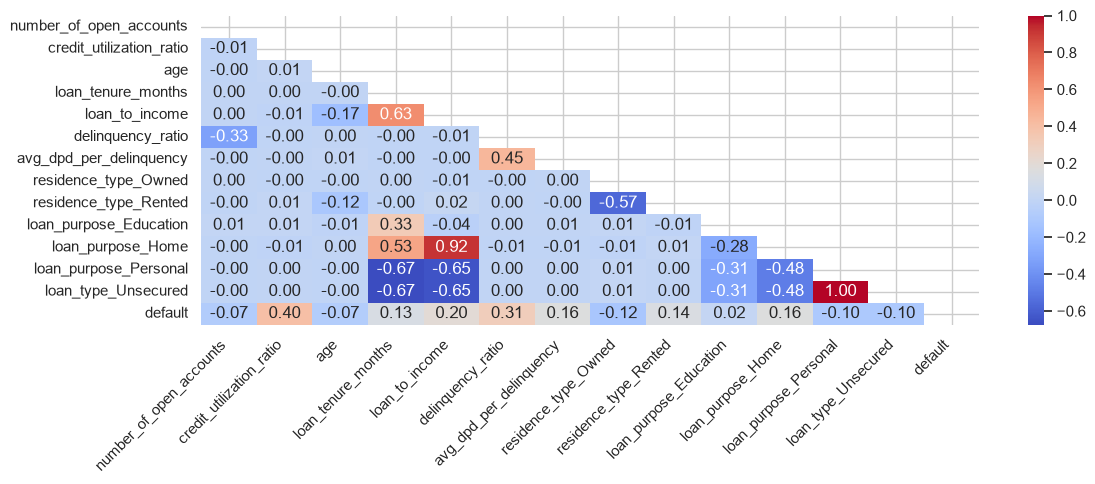

In [ ]:
# Check Correlation

corr = df_transformed.corr()

plt.figure(figsize=(12, 5))
mask = np.triu(np.ones_like(corr, dtype=bool), k=0)
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', mask=mask)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
# Let's drop loan_type altogether, it is practically same as loan_purpose_Personal
#   This means whenever loan purpose is Personal, the load_type is Unsecured

# loan_purpose_Home needs to go too : FunctionTransformer() required after ColumnTransformer() in a Pipeline()

In [ ]:
# Dropping loan_type

df = df.drop(columns=['loan_type'])

# Updating the list of Categorical Features
cat_features = ['residence_type', 'loan_purpose']

In [ ]:
# dropping loan_purpose_Home

# VERY IMPORTANT : Create the feature_transformation object again before running this cell because cat_features have changed

def drop_generated_column(input_df):
    return input_df.drop(columns=['loan_purpose_Home'])

preprocessing = Pipeline([
    ('transform_features', feature_transformation),
    ('drop_specific_column', FunctionTransformer(drop_generated_column))
])

In [ ]:
df_transformed = preprocessing.fit_transform(df)

In [135]:
df_transformed

,number_of_open_accounts,credit_utilization_ratio,age,loan_tenure_months,loan_to_income,delinquency_ratio,avg_dpd_per_delinquency,residence_type_Owned,residence_type_Rented,loan_purpose_Education,loan_purpose_Personal,default
22383,1.34,0.02,-0.77,-1.20,-0.66,-0.02,0.79,0.00,1.00,0.00,1.00,0
34241,-1.34,0.16,0.35,-1.28,-1.04,-0.39,-0.11,1.00,0.00,0.00,1.00,0
49178,-1.34,1.11,1.37,-0.64,-1.04,0.39,0.58,1.00,0.00,0.00,1.00,0
15721,0.44,0.16,-0.87,-0.40,-0.54,-0.60,-1.14,0.00,0.00,0.00,0.00,0
7447,1.34,1.25,-0.26,1.45,1.37,0.40,0.88,0.00,1.00,0.00,0.00,1
...,...,...,...,...,...,...,...,...,...,...,...,...
17978,-1.34,1.76,0.25,-0.08,1.57,2.12,1.49,0.00,0.00,0.00,0.00,1
19775,0.44,0.67,0.05,-0.72,-0.83,-0.60,-1.14,1.00,0.00,0.00,1.00,0
14750,-1.34,0.47,1.06,0.73,1.52,1.11,0.67,0.00,0.00,0.00,0.00,1
7919,-1.34,-1.10,1.16,0.41,-0.29,-0.60,-1.14,1.00,0.00,1.00,0.00,0


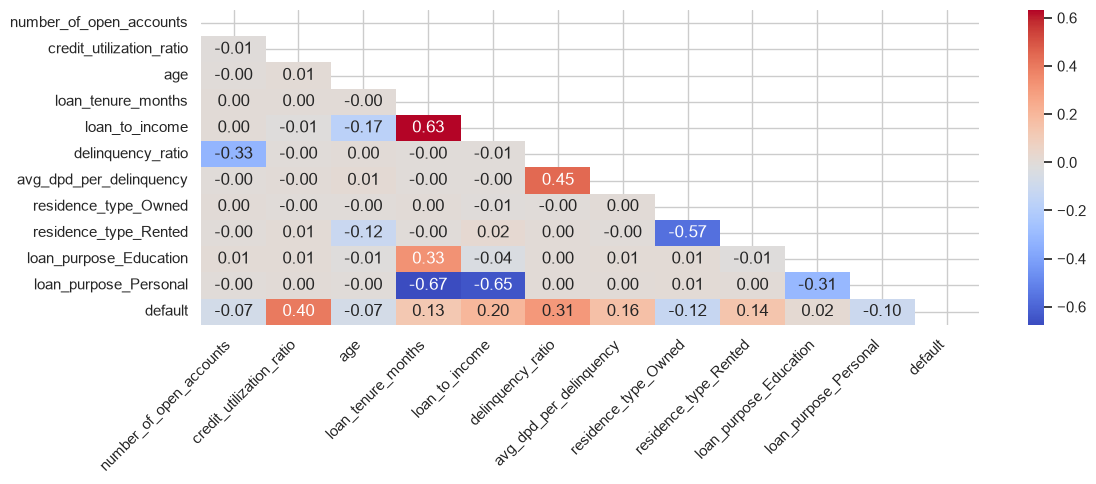

In [137]:
# Check Correlation

corr = df_transformed.corr()

plt.figure(figsize=(12, 5))
mask = np.triu(np.ones_like(corr, dtype=bool), k=0)
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', mask=mask)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [138]:
# Let's do VIF now on df_transformed

In [139]:
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

def calculate_vif(data):
    X_const = sm.add_constant(data)     # 'const' column added to the input dataframe (for intercept)
    
    vif_df = pd.DataFrame()
    vif_df['Column'] = X_const.columns
    vif_df['VIF'] = [variance_inflation_factor(X_const.values, i) for i in range(X_const.shape[1])]

    vif_df = vif_df[vif_df['Column']!='const'].reset_index(drop=True)   # dropping VIF for the constant term because it's meaningless
    
    return vif_df

In [141]:
calculate_vif(df_transformed.drop(columns=['default']))

,Column,VIF
0,number_of_open_accounts,1.15
1,credit_utilization_ratio,1.00
2,age,1.10
3,loan_tenure_months,2.36
4,loan_to_income,2.56
5,delinquency_ratio,1.44
6,avg_dpd_per_delinquency,1.29
7,residence_type_Owned,1.48
8,residence_type_Rented,1.50
9,loan_purpose_Education,1.41


In [ ]:
# calculate_vif(df[num_features].drop(columns=['principal_outstanding']))

__`Features selected for Model Training : `__
- `number_of_open_accounts`
- `credit_utilization_ratio`
- `age`
- `loan_tenure_months`
- `loan_to_income`
- `delinquency_ratio`
- `avg_dpd_per_delinquency`
- `residence_type`
- `loan_purpose`

#### `Exporting data for Model Training & evaluation`

In [102]:
X_train.to_csv("training_data/X_train.csv")               # I'll save the index
X_test.to_csv("training_data/X_test.csv")
y_train.to_csv("training_data/y_train.csv")
y_test.to_csv("training_data/y_test.csv")

In [103]:
X_train.shape, X_test.shape

((34994, 18), (14998, 18))

#### `Rough Work`

<Axes: xlabel='default', ylabel='loan_to_income'>

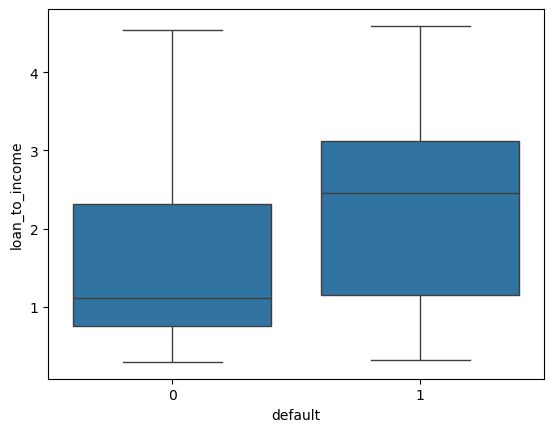

In [ ]:
sns.boxplot(x=df['default'], y=df['loan_to_income'])

<Axes: xlabel='default', ylabel='loan_to_income'>

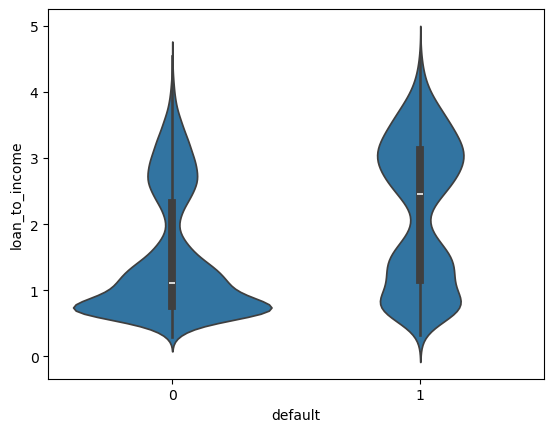

In [ ]:
sns.violinplot(x=df['default'], y=df['loan_to_income'])

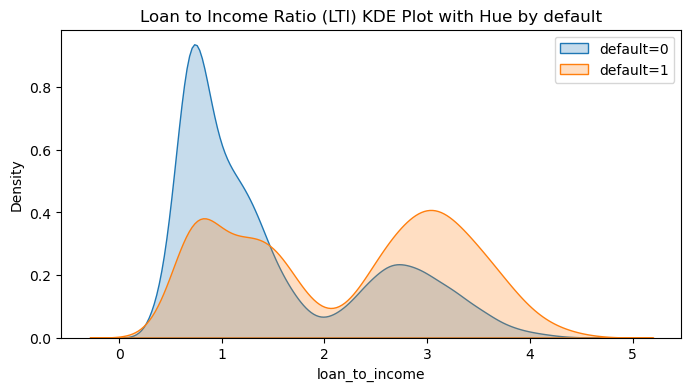

In [ ]:
plt.figure(figsize=(8, 4))
sns.kdeplot(df['loan_to_income'][df['default'] == 0], fill=True, label='default=0')
sns.kdeplot(df['loan_to_income'][df['default'] == 1], fill=True, label='default=1')
plt.title(f"Loan to Income Ratio (LTI) KDE Plot with Hue by default")
plt.legend()
plt.show()

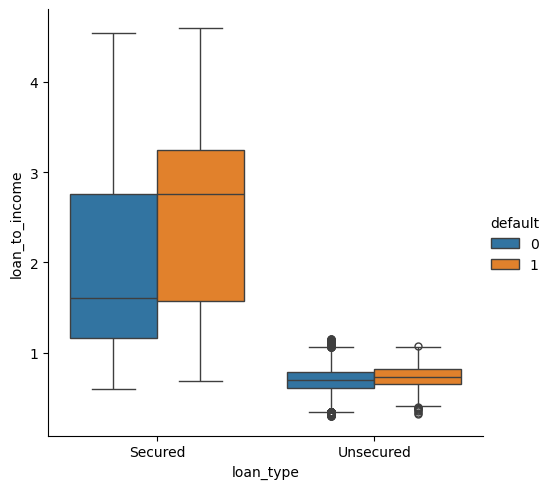

In [ ]:
sns.catplot(x=df['loan_type'], y=df['loan_to_income'], hue=df['default'], kind='box')

In [ ]:
tempDF = pd.DataFrame(
    {
        'Yes' : [11,7,6,12],
        'No' : [2,1,3,2]
    }
)

tempDF['c1'] = tempDF['Yes']/tempDF['Yes'].sum()
tempDF['c2'] = tempDF['No']/tempDF['No'].sum()

tempDF['c3'] = np.log(tempDF['c1']/tempDF['c2'])

tempDF['c4'] = tempDF['c3']*(tempDF['c1']-tempDF['c2'])

tempDF['c5'] = np.log(tempDF['c2']/tempDF['c1'])
tempDF['c6'] = tempDF['c5']*(tempDF['c2']-tempDF['c1'])

tempDF

,Yes,No,c1,c2,c3,c4,c5,c6
0,11,2,0.31,0.25,0.20,0.01,-0.20,0.01
1,7,1,0.19,0.12,0.44,0.03,-0.44,0.03
2,6,3,0.17,0.38,-0.81,0.17,0.81,0.17
3,12,2,0.33,0.25,0.29,0.02,-0.29,0.02


In [ ]:
np.log(4/11), np.log(11/4)

(-1.0116009116784799, 1.0116009116784799)

In [ ]:
# Train Test Split
# Drop features decided after eda
# Encoding
# Scaling
# Multicollinearity - vif - drop if required
# drop categorical features after woe & iv analysis
# this is an imbalanced dataset - handle it

# Pipeline ColumnTransformer

Feature Engineering : Feature Transformation - Encoding, Scaling

#### `Notes`

`Why do NBFCs create their own credit score when they can get it from CIBIL?`

> `NBFCs create their own credit score because they look beyond just the CIBIL score to assess creditworthiness by including alternative data like income, employment history, and internal repayment data, which helps them serve a wider customer base. This allows them to lend to individuals with low or no credit history who may not qualify for traditional loans, and to build a more holistic profile than what a single credit bureau score can provide`

`Drop Columns after EDA, not before [As a principle]`

`Do train test split and then merge xtrain and yrain into a df and then do EDA on this df`

`Numerical Features : histplot | kdeplot | boxplot`